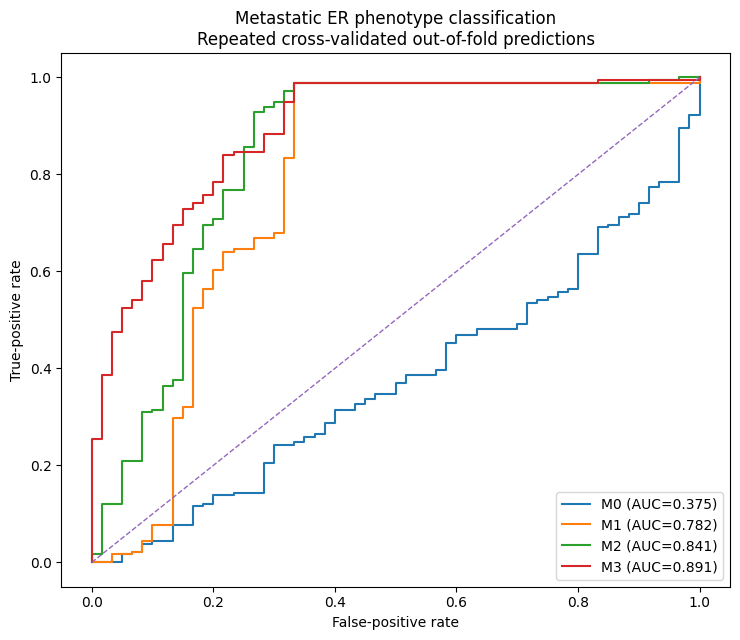

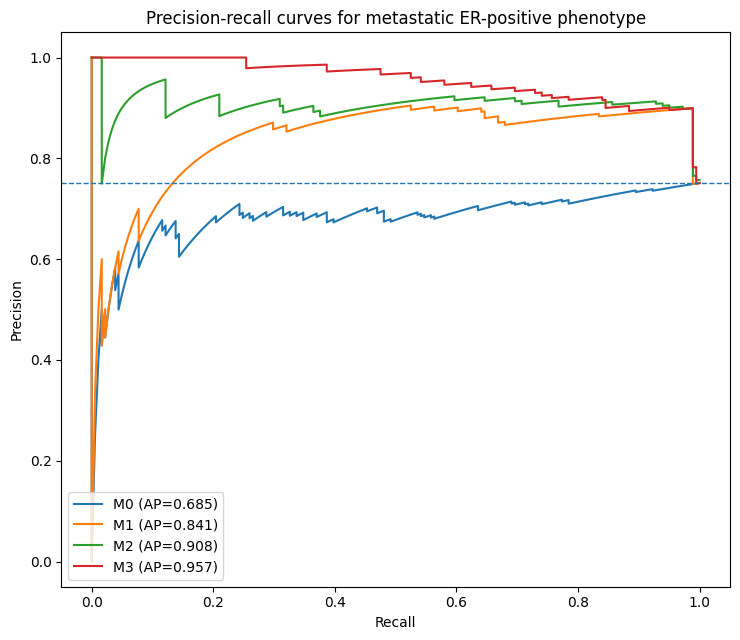

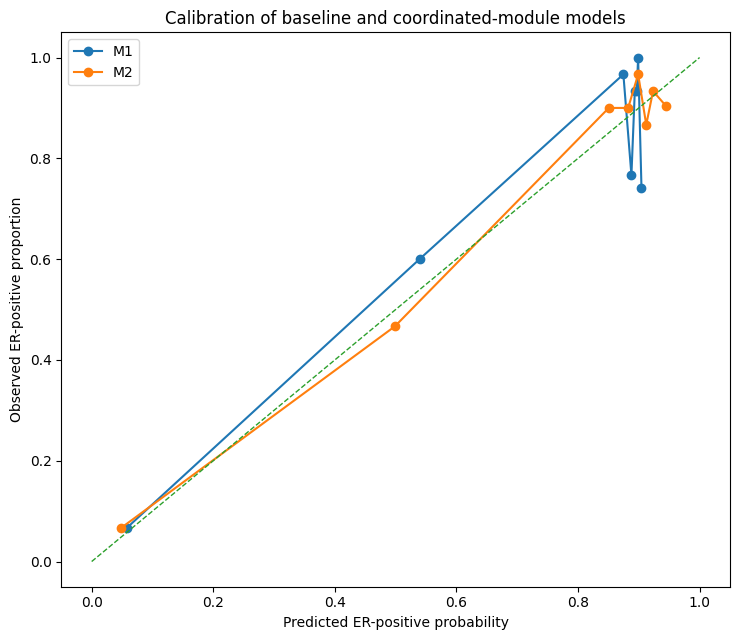

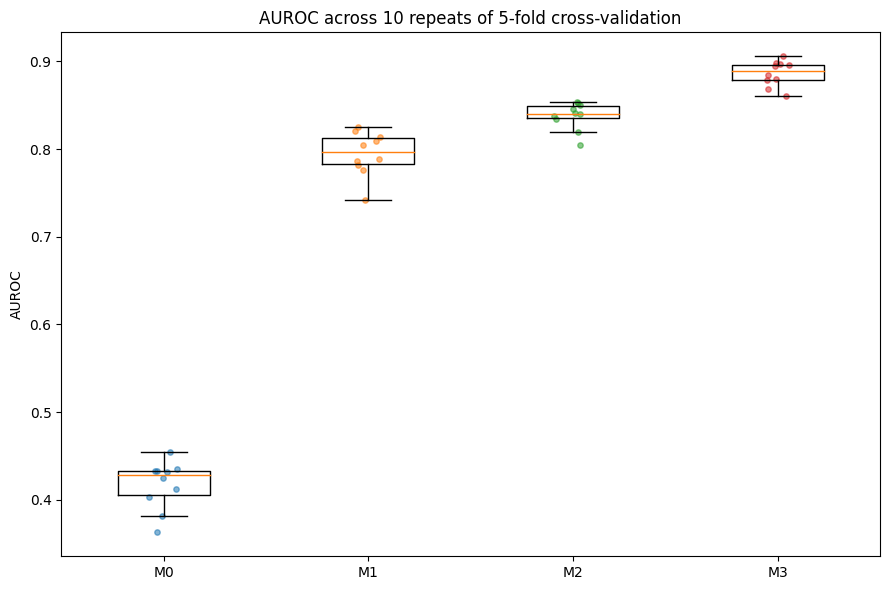

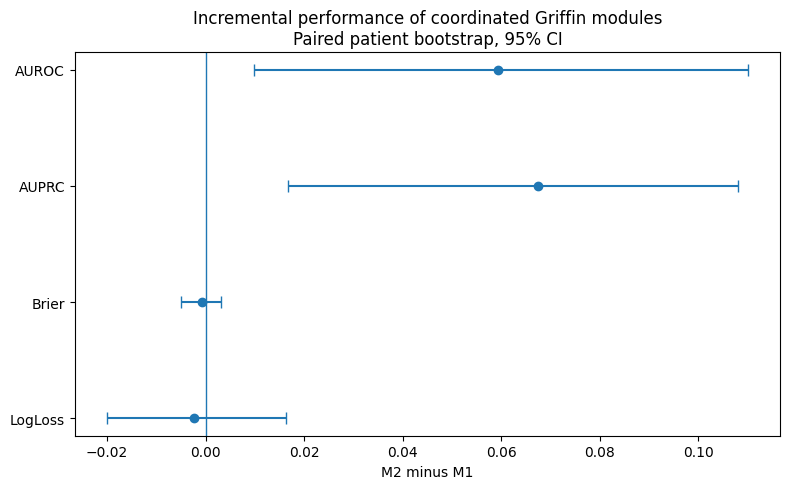

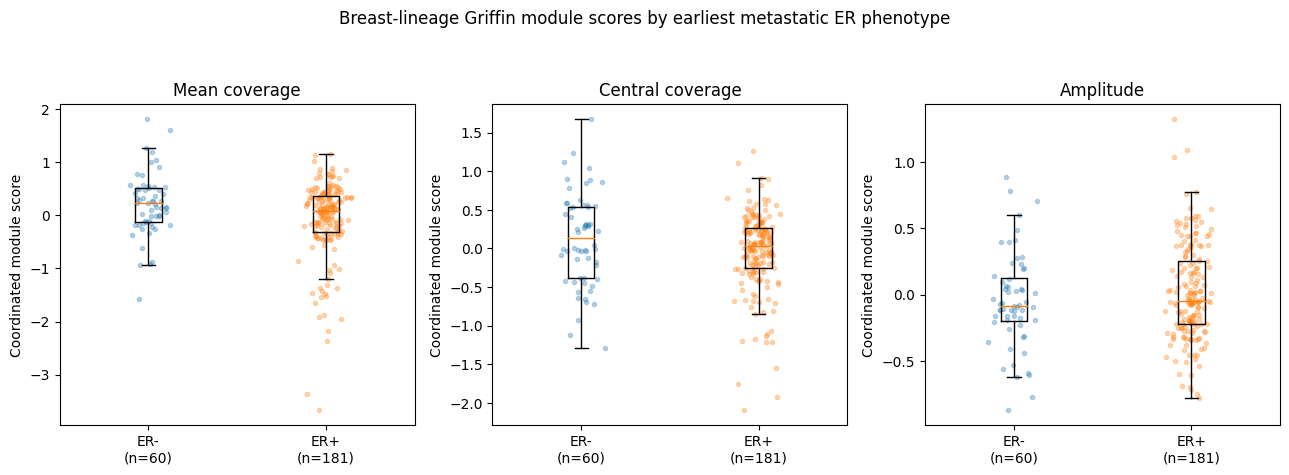

Saved workbook: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Griffin/Downstream/AURORA_Griffin_Incremental_Metastatic_ER/AURORA_Griffin_incremental_ER_model_results.xlsx
{
  "n": 241,
  "ER_positive": 181,
  "ER_negative": 60,
  "discordant": 22,
  "M1_AUROC": 0.781767955801105,
  "M2_AUROC": 0.8411602209944752,
  "M2_minus_M1_AUROC": 0.05939226519337015
}


In [11]:
"""
AURORA Griffin incremental metastatic ER phenotype analysis
============================================================

BIOLOGICAL QUESTION
Does a coordinated breast-lineage TFBS nucleosome signal add information about
earliest known metastatic-diagnosis ER phenotype beyond historical primary-tumor
ER status and plasma tumor fraction?

COHORT AND LABELS
1. Select the lowest available NB cfDNA draw for each patient.
2. Historical primary ER is the first available First_Primary ER result.
3. The outcome is the earliest known Positive/Negative ER result after ordering
   all Met_Diagnosis records by Days_From_Primary_Diagnosis. Missing/unknown
   metastatic records are skipped until a known result is found.
4. Match TFx and Griffin features to the selected cfDNA draw.
5. Use a shared complete cohort for all four models.

MODELS
M0: TFx only.
M1: Primary-tumor ER + TFx.                         [baseline]
M2: M1 + three coordinated breast-lineage modules. [main expanded]
    Each module averages training-fold-standardized values across all 11 TFBS
    for mean coverage, central coverage, or amplitude.
M3: M1 + ESR1/FOXA1/GATA3 x three Griffin metrics.  [9-feature sensitivity]

VALIDATION
- Ridge logistic regression (L2).
- Repeated stratified cross-validation: 5 folds x 10 repeats.
- Prespecified ridge penalty C=1; no data-driven hyperparameter tuning.
- Scaling and module construction occur inside training data only.
- Primary comparison: M2 versus M1 using paired patient bootstrap.
- Report AUROC, AUPRC, Brier score, log loss, calibration, out-of-fold
  predictions, and discordance-group performance.

REQUIRED PACKAGES
openpyxl, numpy, scipy, scikit-learn, statsmodels, matplotlib
"""
import os, re, math, csv, json, shutil, zipfile
import xml.etree.ElementTree as ET
from collections import defaultdict, Counter
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import logit
import statsmodels.api as sm
from openpyxl import Workbook
from openpyxl.styles import Alignment, Border, Font, PatternFill, Side
from openpyxl.utils import get_column_letter
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss,
                             log_loss, roc_curve, precision_recall_curve,
                             confusion_matrix)
from sklearn.calibration import calibration_curve

# ----------------------------- PATHS -----------------------------
CLINICAL_FILE = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Clinical_data/AUP_ClinicalData_20260609.xlsx"
TFX_FILE = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Clinical_data/Metasheet_Analysis.with_Histology_Receptor_status.Earliest_Met_Diagnosis.xlsx"
GRIFFIN_FILE = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Griffin/griffin_nucleosome_profiling/Griffin_30TF_GC_corrected_summary_by_module.xlsx"
OUTDIR = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Griffin/Downstream/AURORA_Griffin_Incremental_Metastatic_ER"
# ---------------------------------------------------------------------

TF_ORDER = ["ESR1","FOXA1","GATA3","PGR","GRHL2","STAT3","NFKB1","TFAP2C","XBP1","FOXM1","FOXO3"]
METRICS = ["mean_coverage","central_coverage","amplitude"]
CORE_TFS = ["ESR1","FOXA1","GATA3"]
MODEL_NAMES = [
    "M0: TFx only",
    "M1: Primary ER + TFx",
    "M2: M1 + 3 coordinated modules",
    "M3: M1 + ESR1/FOXA1/GATA3 x 3",
]

def norm_status(v):
    if v is None: return None
    s = str(v).strip().lower()
    if s in {"positive","pos","+","positive (+)","positive/pos"}: return "Positive"
    if s in {"negative","neg","-","negative (-)","negative/neg"}: return "Negative"
    return None

def norm_id(v):
    if v is None: return None
    if isinstance(v, float) and v.is_integer(): return str(int(v))
    return str(v).strip()

def safe_float(v):
    if v is None: return None
    try:
        x = float(str(v).replace(",","").replace("%","").strip())
        return x if np.isfinite(x) else None
    except Exception:
        return None

def read_values(path, sheet_name, cell_range):
    """Fast read-only XLSX reader using Python standard-library XML parsing."""
    def col_num(ref):
        letters=re.match(r"([A-Z]+)",ref).group(1)
        n=0
        for ch in letters: n=n*26+(ord(ch)-64)
        return n
    a,b=cell_range.split(":")
    min_col,min_row=col_num(a),int(re.search(r"\d+",a).group())
    max_col,max_row=col_num(b),int(re.search(r"\d+",b).group())
    ns={"m":"http://schemas.openxmlformats.org/spreadsheetml/2006/main",
        "r":"http://schemas.openxmlformats.org/officeDocument/2006/relationships",
        "pr":"http://schemas.openxmlformats.org/package/2006/relationships"}
    with zipfile.ZipFile(path) as z:
        shared=[]
        if "xl/sharedStrings.xml" in z.namelist():
            root=ET.fromstring(z.read("xl/sharedStrings.xml"))
            for si in root.findall("m:si",ns):
                shared.append("".join(t.text or "" for t in si.findall(".//m:t",ns)))
        wbroot=ET.fromstring(z.read("xl/workbook.xml"))
        rid=None
        for sh in wbroot.findall("m:sheets/m:sheet",ns):
            if sh.attrib.get("name")==sheet_name:
                rid=sh.attrib.get("{http://schemas.openxmlformats.org/officeDocument/2006/relationships}id")
                break
        if rid is None: raise KeyError(f"Sheet not found: {sheet_name}")
        relroot=ET.fromstring(z.read("xl/_rels/workbook.xml.rels"))
        target=None
        for rel in relroot.findall("pr:Relationship",ns):
            if rel.attrib.get("Id")==rid: target=rel.attrib.get("Target"); break
        if target is None: raise KeyError(f"Relationship not found for {sheet_name}")
        sheet_path=target.lstrip("/") if target.startswith("/") else ("xl/"+target if not target.startswith("xl/") else target)
        root=ET.fromstring(z.read(sheet_path))
        out=[[None]*(max_col-min_col+1) for _ in range(max_row-min_row+1)]
        for c in root.findall(".//m:sheetData/m:row/m:c",ns):
            ref=c.attrib.get("r"); row=int(re.search(r"\d+",ref).group()); col=col_num(ref)
            if row<min_row or row>max_row or col<min_col or col>max_col: continue
            typ=c.attrib.get("t"); v=c.find("m:v",ns); value=None
            if typ=="inlineStr":
                value="".join(t.text or "" for t in c.findall(".//m:t",ns))
            elif v is not None:
                raw=v.text
                if typ=="s": value=shared[int(raw)]
                elif typ in {"str","e"}: value=raw
                elif typ=="b": value=(raw=="1")
                else:
                    try:
                        f=float(raw); value=int(f) if f.is_integer() else f
                    except Exception: value=raw
            out[row-min_row][col-min_col]=value
        return out

def rows_from_matrix(mat, header_row=0, data_start=None):
    if data_start is None: data_start = header_row + 1
    headers = [None if x is None else str(x).strip() for x in mat[header_row]]
    out=[]
    for row in mat[data_start:]:
        if not row or all(x is None for x in row): continue
        out.append({h:v for h,v in zip(headers,row) if h is not None})
    return out

def write_tsv(path, rows):
    if not rows: return
    cols=list(rows[0].keys())
    with open(path,"w",newline="") as f:
        w=csv.DictWriter(f,fieldnames=cols,delimiter="\t",extrasaction="ignore")
        w.writeheader(); w.writerows(rows)

def bootstrap_ci(y,p,func,n_boot=500,seed=1234):
    rng=np.random.default_rng(seed); n=len(y); vals=[]
    for _ in range(n_boot):
        ix=rng.integers(0,n,n); yy=y[ix]
        if len(np.unique(yy))<2: continue
        try: vals.append(func(yy,p[ix]))
        except Exception: pass
    return np.percentile(vals,[2.5,97.5]) if vals else [np.nan,np.nan]

def paired_delta(y,p1,p2,func,n_boot=800,seed=1234):
    rng=np.random.default_rng(seed); n=len(y); vals=[]
    for _ in range(n_boot):
        ix=rng.integers(0,n,n); yy=y[ix]
        if len(np.unique(yy))<2: continue
        try: vals.append(func(yy,p2[ix])-func(yy,p1[ix]))
        except Exception: pass
    vals=np.asarray(vals)
    return float(func(y,p2)-func(y,p1)), float(np.percentile(vals,2.5)), float(np.percentile(vals,97.5)), float(2*min(np.mean(vals<=0),np.mean(vals>=0)))

def calibration_stats(y,p):
    lp=logit(np.clip(p,1e-6,1-1e-6))
    fit=sm.GLM(y,sm.add_constant(lp),family=sm.families.Binomial()).fit()
    return float(fit.params[0]),float(fit.params[1])

def threshold_stats(y,p,threshold=0.5):
    pred=(p>=threshold).astype(int)
    tn,fp,fn,tp=confusion_matrix(y,pred,labels=[0,1]).ravel()
    return (tp/(tp+fn) if tp+fn else np.nan,
            tn/(tn+fp) if tn+fp else np.nan,
            tp/(tp+fp) if tp+fp else np.nan,
            tn/(tn+fn) if tn+fn else np.nan)

def excel_value(value):
    """Convert NumPy and non-finite values into Excel-safe Python values."""
    if isinstance(value, np.generic):
        value = value.item()
    if isinstance(value, float) and not math.isfinite(value):
        return None
    if isinstance(value, (list, dict, tuple, set)):
        return str(value)
    return value


def style_header(ws, row_number=1):
    """Apply a consistent report-header style."""
    fill = PatternFill("solid", fgColor="1F4E78")
    font = Font(color="FFFFFF", bold=True)
    border_side = Side(style="thin", color="D9E1F2")
    border = Border(left=border_side, right=border_side,
                    top=border_side, bottom=border_side)
    for cell in ws[row_number]:
        cell.fill = fill
        cell.font = font
        cell.alignment = Alignment(horizontal="center", vertical="center",
                                   wrap_text=True)
        cell.border = border


def set_column_widths(ws, minimum=10, maximum=35):
    """Set readable, bounded widths from populated cell contents."""
    for column_cells in ws.columns:
        letter = get_column_letter(column_cells[0].column)
        max_length = 0
        for cell in column_cells:
            if cell.value is not None:
                max_length = max(max_length, len(str(cell.value)))
        ws.column_dimensions[letter].width = min(max(max_length + 2, minimum), maximum)


def add_sheet(wb, name, rows):
    """Create a formatted worksheet from a list of dictionaries."""
    ws = wb.create_sheet(title=name)
    if not rows:
        return ws

    columns = list(rows[0].keys())
    ws.append(columns)
    for row in rows:
        ws.append([excel_value(row.get(column)) for column in columns])

    style_header(ws)
    ws.freeze_panes = "A2"
    ws.auto_filter.ref = ws.dimensions
    set_column_widths(ws)
    return ws

os.makedirs(OUTDIR,exist_ok=True)

# Read workbooks.
clinical=rows_from_matrix(read_values(CLINICAL_FILE,"AUP_ClinicalData_20260609.NO.DA","A1:AE6729"))
meta=rows_from_matrix(read_values(TFX_FILE,"Sheet1","A1:S770"))
gmat=read_values(GRIFFIN_FILE,"Breast_Lineage","A1:AH771")
gheaders=[None if x is None else str(x).strip() for x in gmat[1]]
griffin={}
for row in gmat[2:]:
    if not row or row[0] is None: continue
    sample=re.sub(r"^AUP-","",str(row[0]).strip(),flags=re.I)
    d={"sample":sample}
    for h,v in zip(gheaders[1:],row[1:]):
        if h: d[h]=safe_float(v)
    griffin[sample]=d

# Clinical labels.
clinical_by_patient=defaultdict(list)
for r in clinical:
    pid=norm_id(r.get("patient_id"))
    if pid:
        r["patient_id"]=pid; clinical_by_patient[pid].append(r)
primary_er={}; earliest_met_er={}; earliest_met_day={}; histories={}
for pid,recs in clinical_by_patient.items():
    prim=[]
    for r in recs:
        if str(r.get("Category")).strip()=="First_Primary":
            day=safe_float(r.get("Days_From_Primary_Diagnosis")); prim.append((day if day is not None else math.inf,r))
    prim.sort(key=lambda x:x[0])
    primary_er[pid]=norm_status(prim[0][1].get("ER_Status")) if prim else None
    mets=[]
    for r in recs:
        if str(r.get("Category")).strip()!="Met_Diagnosis": continue
        day=safe_float(r.get("Days_From_Primary_Diagnosis"))
        if day is not None: mets.append((day,norm_status(r.get("ER_Status"))))
    mets.sort(key=lambda x:x[0]); histories[pid]=mets
    known=[x for x in mets if x[1] in {"Positive","Negative"}]
    earliest_met_day[pid]=known[0][0] if known else None
    earliest_met_er[pid]=known[0][1] if known else None

# First draw and merged cohort.
by_patient=defaultdict(list)
for r in meta:
    pid=norm_id(r.get("Patient_id")); sid=r.get("Collaborator_sample_id")
    if not pid or sid is None: continue
    sample=re.sub(r"^AUP-","",str(sid).strip(),flags=re.I)
    m=re.search(r"-NB(\d+)$",sample,re.I)
    if not m: continue
    rr=dict(r); rr.update({"patient_id":pid,"sample":sample,"NB":int(m.group(1))})
    by_patient[pid].append(rr)
first_draw={pid:min(rows,key=lambda z:z["NB"]) for pid,rows in by_patient.items()}
feature_names=[f"{tf}_{m}" for tf in TF_ORDER for m in METRICS]
cohort=[]
for pid,mr in first_draw.items():
    gd=griffin.get(mr["sample"],{})
    tf=safe_float(mr.get("Tumor_Fraction"))
    hist=[er for _,er in histories.get(pid,[]) if er in {"Positive","Negative"}]
    row={"patient_id":pid,"sample":mr["sample"],"NB":mr["NB"],
         "Primary_tumor_ER":primary_er.get(pid),"Metastatic_ER":earliest_met_er.get(pid),
         "Earliest_known_met_ER_day":earliest_met_day.get(pid),
         "TFx_pct":tf*100 if tf is not None else None,
         "Met_ER_ever_changed":len(set(hist))>1}
    for fn in feature_names: row[fn]=gd.get(fn)
    cohort.append(row)

complete=[]
for r in cohort:
    if r["Primary_tumor_ER"] not in {"Positive","Negative"}: continue
    if r["Metastatic_ER"] not in {"Positive","Negative"}: continue
    if r["TFx_pct"] is None: continue
    if any(r.get(fn) is None for fn in feature_names): continue
    complete.append(r)

n=len(complete)
y=np.array([r["Metastatic_ER"]=="Positive" for r in complete],int)
primary=np.array([r["Primary_tumor_ER"]=="Positive" for r in complete],float)
tfx=np.array([r["TFx_pct"] for r in complete],float)
X33=np.array([[r[fn] for fn in feature_names] for r in complete],float)
X9=np.array([[r[f"{tf}_{m}"] for tf in CORE_TFS for m in METRICS] for r in complete],float)
metric_indices={m:[feature_names.index(f"{tf}_{m}") for tf in TF_ORDER] for m in METRICS}

# Repeated stratified cross-validation.
n_repeats=10
outer=RepeatedStratifiedKFold(n_splits=5,n_repeats=n_repeats,random_state=20260803)
C_FIXED=1.0
preds={name:np.full((n_repeats,n),np.nan) for name in MODEL_NAMES}
best_C={name:[] for name in MODEL_NAMES}
for split_id,(tr,te) in enumerate(outer.split(np.zeros(n),y)):
    rep=split_id//5
    mu=X33[tr].mean(axis=0); sd=X33[tr].std(axis=0); sd[sd==0]=1
    ztr=(X33[tr]-mu)/sd; zte=(X33[te]-mu)/sd
    mod_tr=np.column_stack([ztr[:,metric_indices[m]].mean(axis=1) for m in METRICS])
    mod_te=np.column_stack([zte[:,metric_indices[m]].mean(axis=1) for m in METRICS])
    designs={
      MODEL_NAMES[0]:(tfx[tr,None],tfx[te,None]),
      MODEL_NAMES[1]:(np.column_stack([primary[tr],tfx[tr]]),np.column_stack([primary[te],tfx[te]])),
      MODEL_NAMES[2]:(np.column_stack([primary[tr],tfx[tr],mod_tr]),np.column_stack([primary[te],tfx[te],mod_te])),
      MODEL_NAMES[3]:(np.column_stack([primary[tr],tfx[tr],X9[tr]]),np.column_stack([primary[te],tfx[te],X9[te]])),
    }
    for name,(Xtr,Xte) in designs.items():
        pipe=Pipeline([("scale",StandardScaler()),("model",LogisticRegression(C=C_FIXED,solver="liblinear",max_iter=5000))])
        pipe.fit(Xtr,y[tr])
        preds[name][rep,te]=pipe.predict_proba(Xte)[:,1]
        best_C[name].append(C_FIXED)
for name in MODEL_NAMES:
    if np.isnan(preds[name]).any(): raise RuntimeError(f"Incomplete OOF predictions: {name}")

# Metrics.
metric_rows=[]; mean_pred={}
for name in MODEL_NAMES:
    mean_pred[name]=preds[name].mean(axis=0)
    for rep in range(n_repeats):
        p=preds[name][rep]; intercept,slope=calibration_stats(y,p); sens,spec,ppv,npv=threshold_stats(y,p)
        metric_rows.append({"model":name,"repeat":rep+1,"AUROC":roc_auc_score(y,p),
          "AUPRC":average_precision_score(y,p),"Brier":brier_score_loss(y,p),
          "LogLoss":log_loss(y,p,labels=[0,1]),"Calibration_intercept":intercept,
          "Calibration_slope":slope,"Sensitivity_0.5":sens,"Specificity_0.5":spec,
          "PPV_0.5":ppv,"NPV_0.5":npv})
summary_rows=[]
for name in MODEL_NAMES:
    p=mean_pred[name]; auc_ci=bootstrap_ci(y,p,roc_auc_score); ap_ci=bootstrap_ci(y,p,average_precision_score); br_ci=bootstrap_ci(y,p,brier_score_loss)
    intercept,slope=calibration_stats(y,p); rr=[r for r in metric_rows if r["model"]==name]
    summary_rows.append({"model":name,"n":n,"ER_positive":int(y.sum()),"ER_negative":int((1-y).sum()),
      "Pooled_OOF_AUROC":roc_auc_score(y,p),"AUROC_CI_low":auc_ci[0],"AUROC_CI_high":auc_ci[1],
      "Pooled_OOF_AUPRC":average_precision_score(y,p),"AUPRC_CI_low":ap_ci[0],"AUPRC_CI_high":ap_ci[1],
      "Pooled_OOF_Brier":brier_score_loss(y,p),"Brier_CI_low":br_ci[0],"Brier_CI_high":br_ci[1],
      "Pooled_OOF_LogLoss":log_loss(y,p,labels=[0,1]),"Calibration_intercept":intercept,"Calibration_slope":slope,
      "Median_selected_C":float(np.median(best_C[name])),"Mean_repeat_AUROC":float(np.mean([r["AUROC"] for r in rr])),
      "SD_repeat_AUROC":float(np.std([r["AUROC"] for r in rr],ddof=1))})

base=MODEL_NAMES[1]; delta_rows=[]
for comp,label in [(MODEL_NAMES[0],"M0 minus M1"),(MODEL_NAMES[2],"M2 minus M1"),(MODEL_NAMES[3],"M3 minus M1")]:
    for metric,func,direction in [("AUROC",roc_auc_score,"higher"),("AUPRC",average_precision_score,"higher"),
      ("Brier",brier_score_loss,"lower"),("LogLoss",lambda yy,pp:log_loss(yy,pp,labels=[0,1]),"lower")]:
        d,lo,hi,pv=paired_delta(y,mean_pred[base],mean_pred[comp],func)
        delta_rows.append({"comparison":label,"metric":metric,"delta_comparison_minus_M1":d,
          "CI_low":lo,"CI_high":hi,"bootstrap_two_sided_p":pv,"better_direction":direction})

discord=np.array([r["Primary_tumor_ER"]!=r["Metastatic_ER"] for r in complete])
discord_rows=[]
for name in MODEL_NAMES:
    p=mean_pred[name]; pred=(p>=.5).astype(int)
    for group,mask in [("Concordant",~discord),("Discordant",discord)]:
        discord_rows.append({"model":name,"group":group,"n":int(mask.sum()),
          "accuracy_at_0.5":float(np.mean(pred[mask]==y[mask])),
          "mean_predicted_ER_positive_probability":float(np.mean(p[mask]))})
patient_rows=[]
for i,r in enumerate(complete):
    out={"patient_id":r["patient_id"],"sample":r["sample"],"NB":r["NB"],
      "Primary_tumor_ER":r["Primary_tumor_ER"],"Earliest_metastatic_ER":r["Metastatic_ER"],
      "Discordant":bool(discord[i]),"TFx_pct":r["TFx_pct"]}
    for name in MODEL_NAMES: out[name]=float(mean_pred[name][i])
    patient_rows.append(out)

# Descriptive module scores use full-cohort scaling only for plots/tables, not model validation.
mu=X33.mean(axis=0); sd=X33.std(axis=0); sd[sd==0]=1; z=(X33-mu)/sd
mods=np.column_stack([z[:,metric_indices[m]].mean(axis=1) for m in METRICS])
module_rows=[]
for i,r in enumerate(complete):
    module_rows.append({"patient_id":r["patient_id"],"sample":r["sample"],"Primary_tumor_ER":r["Primary_tumor_ER"],
      "Metastatic_ER":r["Metastatic_ER"],"TFx_pct":r["TFx_pct"],"Mean_coverage_module":mods[i,0],
      "Central_coverage_module":mods[i,1],"Amplitude_module":mods[i,2]})

write_tsv(os.path.join(OUTDIR,"Model_performance_summary.tsv"),summary_rows)
write_tsv(os.path.join(OUTDIR,"Repeated_CV_metrics.tsv"),metric_rows)
write_tsv(os.path.join(OUTDIR,"Incremental_model_comparisons.tsv"),delta_rows)
write_tsv(os.path.join(OUTDIR,"Patient_level_out_of_fold_predictions.tsv"),patient_rows)
write_tsv(os.path.join(OUTDIR,"Discordance_performance.tsv"),discord_rows)
write_tsv(os.path.join(OUTDIR,"Descriptive_module_scores.tsv"),module_rows)

# Plots.
fig,ax=plt.subplots(figsize=(7.5,6.5))
for name in MODEL_NAMES:
    fpr,tpr,_=roc_curve(y,mean_pred[name]); ax.plot(fpr,tpr,label=f"{name.split(':')[0]} (AUC={roc_auc_score(y,mean_pred[name]):.3f})")
ax.plot([0,1],[0,1],linestyle="--",linewidth=1); ax.set(xlabel="False-positive rate",ylabel="True-positive rate",title="Metastatic ER phenotype classification\nRepeated cross-validated out-of-fold predictions"); ax.legend(loc="lower right"); fig.tight_layout()
fig.savefig(os.path.join(OUTDIR,"ROC_model_comparison.png"),dpi=300); fig.savefig(os.path.join(OUTDIR,"ROC_model_comparison.pdf")); plt.show(); plt.close(fig)

fig,ax=plt.subplots(figsize=(7.5,6.5))
for name in MODEL_NAMES:
    precision,recall,_=precision_recall_curve(y,mean_pred[name]); ax.plot(recall,precision,label=f"{name.split(':')[0]} (AP={average_precision_score(y,mean_pred[name]):.3f})")
ax.axhline(y.mean(),linestyle="--",linewidth=1); ax.set(xlabel="Recall",ylabel="Precision",title="Precision-recall curves for metastatic ER-positive phenotype"); ax.legend(loc="lower left"); fig.tight_layout()
fig.savefig(os.path.join(OUTDIR,"Precision_recall_model_comparison.png"),dpi=300); fig.savefig(os.path.join(OUTDIR,"Precision_recall_model_comparison.pdf")); plt.show(); plt.close(fig)

fig,ax=plt.subplots(figsize=(7.5,6.5))
for name in [MODEL_NAMES[1],MODEL_NAMES[2]]:
    frac,meanp=calibration_curve(y,mean_pred[name],n_bins=8,strategy="quantile"); ax.plot(meanp,frac,marker="o",label=name.split(":")[0])
ax.plot([0,1],[0,1],linestyle="--",linewidth=1); ax.set(xlabel="Predicted ER-positive probability",ylabel="Observed ER-positive proportion",title="Calibration of baseline and coordinated-module models"); ax.legend(); fig.tight_layout()
fig.savefig(os.path.join(OUTDIR,"Calibration_M1_vs_M2.png"),dpi=300); fig.savefig(os.path.join(OUTDIR,"Calibration_M1_vs_M2.pdf")); plt.show(); plt.close(fig)

fig,ax=plt.subplots(figsize=(9,6)); data=[[r["AUROC"] for r in metric_rows if r["model"]==name] for name in MODEL_NAMES]
ax.boxplot(data,labels=[x.split(":")[0] for x in MODEL_NAMES],showfliers=False)
for j,vals in enumerate(data,1):
    rng=np.random.default_rng(20+j); ax.scatter(rng.normal(j,.04,len(vals)),vals,s=15,alpha=.55)
ax.set(ylabel="AUROC",title=f"AUROC across {n_repeats} repeats of {INNER_FOLDS}-fold cross-validation"); fig.tight_layout()
fig.savefig(os.path.join(OUTDIR,"Repeated_CV_AUROC.png"),dpi=300); fig.savefig(os.path.join(OUTDIR,"Repeated_CV_AUROC.pdf")); plt.show(); plt.close(fig)

pd=[r for r in delta_rows if r["comparison"]=="M2 minus M1"]; fig,ax=plt.subplots(figsize=(8,5)); yy=np.arange(len(pd)); vals=[r["delta_comparison_minus_M1"] for r in pd]; lo=[r["CI_low"] for r in pd]; hi=[r["CI_high"] for r in pd]
ax.errorbar(vals,yy,xerr=[[v-l for v,l in zip(vals,lo)],[h-v for v,h in zip(vals,hi)]],fmt="o",capsize=4); ax.axvline(0,linewidth=1); ax.set_yticks(yy); ax.set_yticklabels([r["metric"] for r in pd]); ax.invert_yaxis(); ax.set(xlabel="M2 minus M1",title="Incremental performance of coordinated Griffin modules\nPaired patient bootstrap, 95% CI"); fig.tight_layout()
fig.savefig(os.path.join(OUTDIR,"Incremental_M2_vs_M1.png"),dpi=300); fig.savefig(os.path.join(OUTDIR,"Incremental_M2_vs_M1.pdf")); plt.show(); plt.close(fig)

fig,axes=plt.subplots(1,3,figsize=(13,4.8))
for j,(lab,col) in enumerate([("Mean coverage","Mean_coverage_module"),("Central coverage","Central_coverage_module"),("Amplitude","Amplitude_module")]):
    neg=[r[col] for r in module_rows if r["Metastatic_ER"]=="Negative"]; pos=[r[col] for r in module_rows if r["Metastatic_ER"]=="Positive"]
    axes[j].boxplot([neg,pos],labels=[f"ER-\n(n={len(neg)})",f"ER+\n(n={len(pos)})"],showfliers=False); rng=np.random.default_rng(100+j); axes[j].scatter(rng.normal(1,.055,len(neg)),neg,s=9,alpha=.3); axes[j].scatter(rng.normal(2,.055,len(pos)),pos,s=9,alpha=.3); axes[j].set_title(lab); axes[j].set_ylabel("Coordinated module score")
fig.suptitle("Breast-lineage Griffin module scores by earliest metastatic ER phenotype"); fig.tight_layout(rect=[0,0,1,.93]); fig.savefig(os.path.join(OUTDIR,"Faceted_module_score_distributions.png"),dpi=300); fig.savefig(os.path.join(OUTDIR,"Faceted_module_score_distributions.pdf")); plt.show(); plt.close(fig)

# Workbook.
wb = Workbook()
readme = wb.active
readme.title = "README"
readme_rows = [
    ["AURORA Griffin incremental metastatic ER analysis", None],
    ["Biological question", "Does a coordinated breast-lineage TFBS nucleosome signal add information about earliest known metastatic-diagnosis ER phenotype beyond historical primary-tumor ER status and plasma tumor fraction?"],
    ["Outcome", "Earliest known Positive/Negative ER across chronologically ordered Met_Diagnosis records."],
    ["Shared cohort", f"n={n}; ER+={int(y.sum())}; ER-={int((1-y).sum())}; discordant={int(discord.sum())}."],
    ["M0", "TFx only"],
    ["M1", "Primary-tumor ER + TFx"],
    ["M2", "M1 + three coordinated module scores built within training folds across all 11 TFBS"],
    ["M3", "M1 + ESR1/FOXA1/GATA3 x three metrics"],
    ["Validation", "Ridge logistic regression with prespecified C=1; repeated stratified 5-fold cross-validation x 10 repeats."],
    ["Primary comparison", "M2 versus M1 using paired patient bootstrap."],
    ["Caution", "Internal validation of phenotype classification; not external validation or proof of conversion detection."],
]
for row in readme_rows:
    readme.append(row)

readme.merge_cells("A1:B1")
readme["A1"].fill = PatternFill("solid", fgColor="1F4E78")
readme["A1"].font = Font(color="FFFFFF", bold=True, size=14)
readme["A1"].alignment = Alignment(horizontal="center", vertical="center")
section_fill = PatternFill("solid", fgColor="D9EAF7")
for row_number in range(2, len(readme_rows) + 1):
    readme.cell(row=row_number, column=1).fill = section_fill
    readme.cell(row=row_number, column=1).font = Font(bold=True)
    readme.cell(row=row_number, column=1).alignment = Alignment(vertical="top", wrap_text=True)
    readme.cell(row=row_number, column=2).alignment = Alignment(vertical="top", wrap_text=True)
readme.column_dimensions["A"].width = 24
readme.column_dimensions["B"].width = 90
readme.freeze_panes = "A2"

add_sheet(wb, "Performance Summary", summary_rows)
add_sheet(wb, "Incremental Comparisons", delta_rows)
add_sheet(wb, "Repeated CV", metric_rows)
add_sheet(wb, "Patient Predictions", patient_rows)
add_sheet(wb, "Discordance", discord_rows)
add_sheet(wb, "Module Scores", module_rows)

xlsx_path = os.path.join(OUTDIR, "AURORA_Griffin_incremental_ER_model_results.xlsx")
wb.save(xlsx_path)
print("Saved workbook:", xlsx_path)

# Report.
smap={r["model"]:r for r in summary_rows}; m1=smap[MODEL_NAMES[1]]; m2=smap[MODEL_NAMES[2]]; m3=smap[MODEL_NAMES[3]]; dm={r["metric"]:r for r in delta_rows if r["comparison"]=="M2 minus M1"}
report=f"""AURORA Griffin incremental metastatic ER phenotype analysis\n=============================================================\n\nShared complete cohort: n={n}\nMetastatic ER-positive: {int(y.sum())}\nMetastatic ER-negative: {int((1-y).sum())}\nPrimary-to-metastatic discordant: {int(discord.sum())}\n\nM1 AUROC: {m1['Pooled_OOF_AUROC']:.3f} ({m1['AUROC_CI_low']:.3f}-{m1['AUROC_CI_high']:.3f})\nM2 AUROC: {m2['Pooled_OOF_AUROC']:.3f} ({m2['AUROC_CI_low']:.3f}-{m2['AUROC_CI_high']:.3f})\nM3 AUROC: {m3['Pooled_OOF_AUROC']:.3f} ({m3['AUROC_CI_low']:.3f}-{m3['AUROC_CI_high']:.3f})\n\nPrimary comparison M2 minus M1:\nDelta AUROC: {dm['AUROC']['delta_comparison_minus_M1']:.4f} ({dm['AUROC']['CI_low']:.4f} to {dm['AUROC']['CI_high']:.4f}); bootstrap p={dm['AUROC']['bootstrap_two_sided_p']:.4g}\nDelta AUPRC: {dm['AUPRC']['delta_comparison_minus_M1']:.4f} ({dm['AUPRC']['CI_low']:.4f} to {dm['AUPRC']['CI_high']:.4f})\nDelta Brier: {dm['Brier']['delta_comparison_minus_M1']:.4f} ({dm['Brier']['CI_low']:.4f} to {dm['Brier']['CI_high']:.4f}); negative favors M2.\n\nInterpretation must emphasize paired incremental estimates. Overall performance may be dominated by primary-metastatic ER concordance; discordant-subgroup results are exploratory.\n"""
with open(os.path.join(OUTDIR,"Detailed_results_and_interpretation.txt"),"w") as f: f.write(report)

manifest=[]
for fn in sorted(os.listdir(OUTDIR)):
    p=os.path.join(OUTDIR,fn)
    if os.path.isfile(p): manifest.append({"file":fn,"bytes":os.path.getsize(p)})
write_tsv(os.path.join(OUTDIR,"File_manifest.tsv"),manifest)
print(json.dumps({"n":n,"ER_positive":int(y.sum()),"ER_negative":int((1-y).sum()),"discordant":int(discord.sum()),"M1_AUROC":m1["Pooled_OOF_AUROC"],"M2_AUROC":m2["Pooled_OOF_AUROC"],"M2_minus_M1_AUROC":dm["AUROC"]["delta_comparison_minus_M1"]},indent=2))

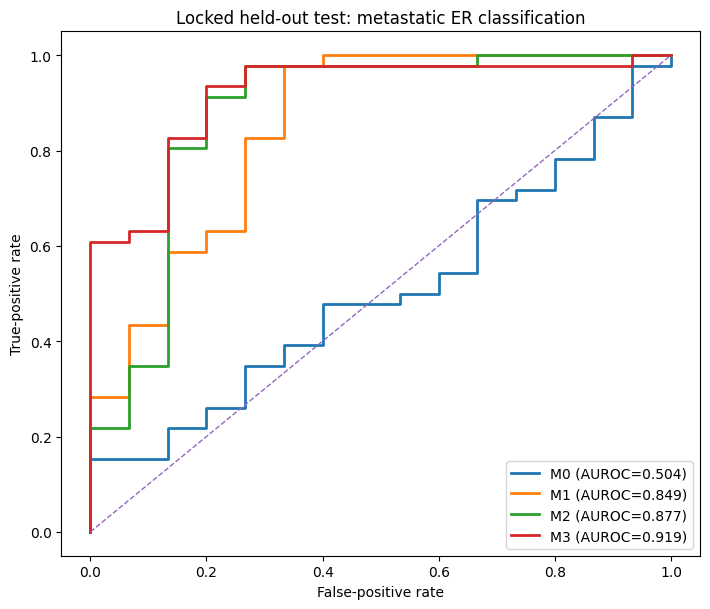

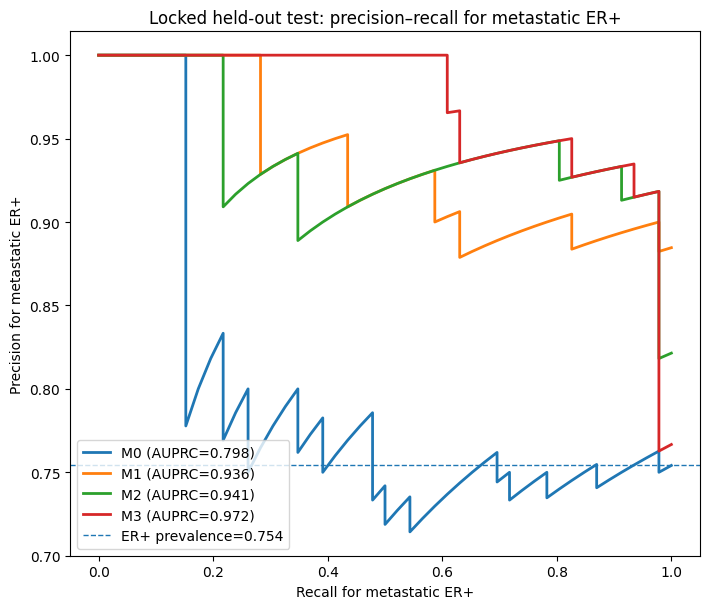

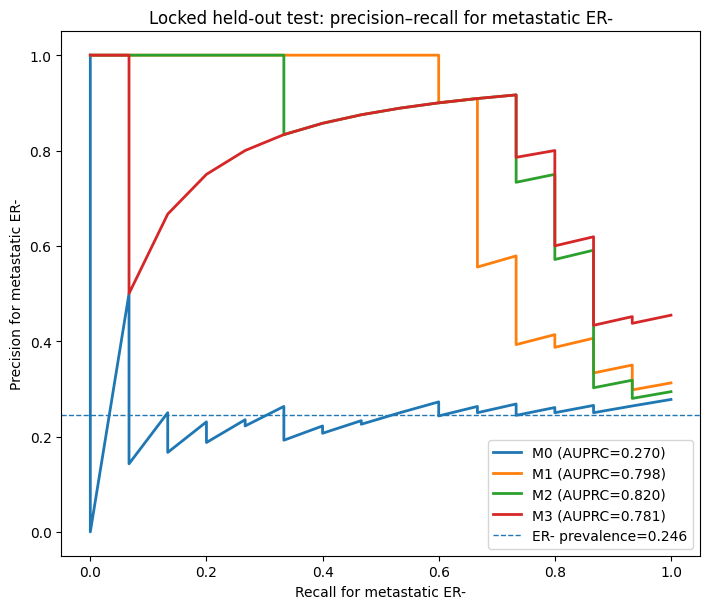

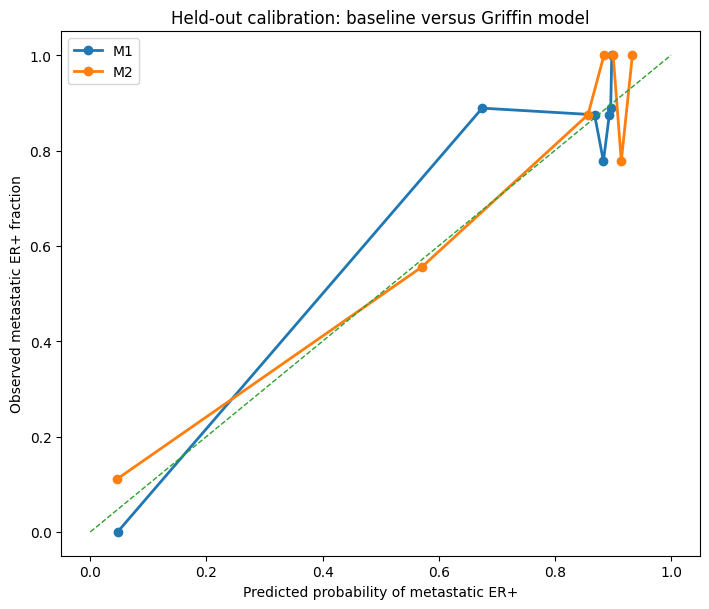

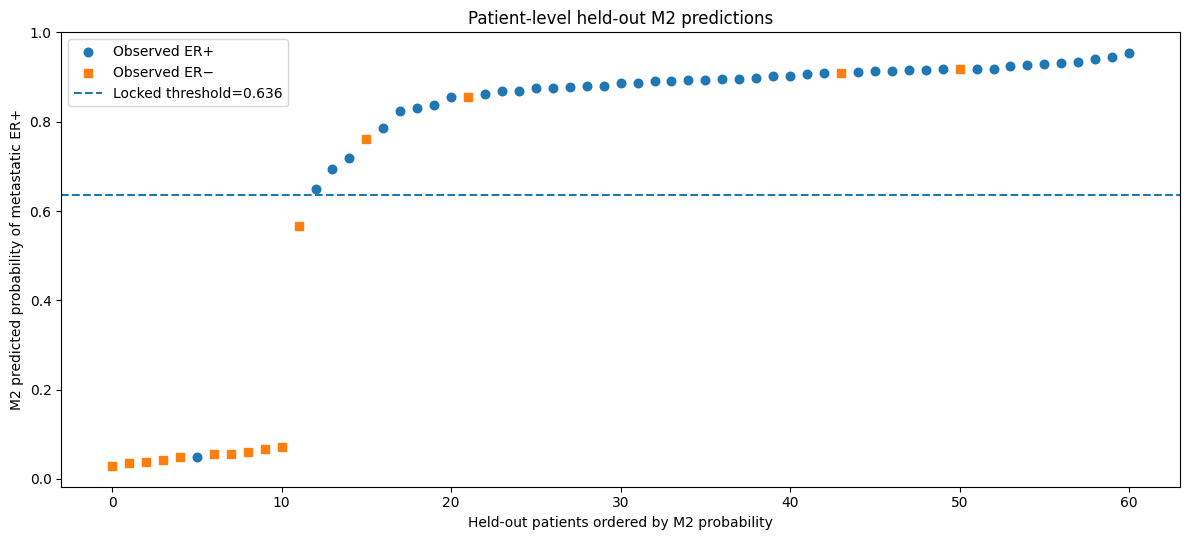


Analysis complete
Development patients: 180
Held-out test patients: 61
M2 correctly classified: 56 / 61
M2 accuracy: 91.8%
Discordant correctly classified by M2: 1 / 6
Outputs: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Griffin/Downstream/AURORA_Griffin_Heldout_Test_ER


In [12]:
"""
AURORA Griffin held-out metastatic ER prediction analysis
=========================================================

This script is self-contained and starts from the three original Excel files.
It creates the feature table internally; PRED_PATH is not required.

Primary question
----------------
Does a coordinated breast-lineage TFBS nucleosome signal add information about
metastatic ER phenotype beyond historical primary-tumor ER status and TFx?

Models
------
M0: TFx
M1: Primary-tumor ER + TFx
M2: M1 + coordinated mean-, central-, and amplitude-module scores across 11 TFBS
M3: M1 + ESR1/FOXA1/GATA3 x 3 Griffin metrics

Validation
----------
75% development / 25% locked held-out test. When SPLIT_PATH exists, its fixed
patient assignment is used to reproduce the same test cohort. Otherwise, a new
jointly stratified split is generated and saved.
"""

from pathlib import Path
import json
import math
import re
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.calibration import calibration_curve
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    brier_score_loss,
    confusion_matrix,
    log_loss,
    precision_recall_curve,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    cross_val_predict,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)

# =============================================================================
# USER SETTINGS: EDIT THESE PATHS
# =============================================================================
CLINICAL_FILE = Path(
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Clinical_data/"
    "AUP_ClinicalData_20260609.xlsx"
)
TFX_FILE = Path(
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Clinical_data/"
    "Metasheet_Analysis.with_Histology_Receptor_status.Earliest_Met_Diagnosis.xlsx"
)
GRIFFIN_FILE = Path(
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Griffin/"
    "griffin_nucleosome_profiling/Griffin_30TF_GC_corrected_summary_by_module.xlsx"
)
OUTDIR = Path(
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Griffin/Downstream/"
    "AURORA_Griffin_Heldout_Test_ER"
)

# Optional fixed split manifest. Copy Cohort_split.tsv to this location to
# reproduce the same 180-development / 61-test cohort used in the meeting plots.
SPLIT_PATH = OUTDIR / "Cohort_split.tsv"

SEED = 1234
TEST_SIZE = 0.25
INNER_FOLDS = 5
C_GRID = np.logspace(-3, 3, 13)
N_BOOT = 2000

TF_ORDER = [
    "ESR1", "FOXA1", "GATA3", "PGR", "GRHL2", "STAT3",
    "NFKB1", "TFAP2C", "XBP1", "FOXM1", "FOXO3",
]
METRICS = ["mean_coverage", "central_coverage", "amplitude"]
CORE_TFS = ["ESR1", "FOXA1", "GATA3"]

MODEL_NAMES = {
    "M0": "M0: TFx only",
    "M1": "M1: Primary ER + TFx",
    "M2": "M2: M1 + 3 coordinated modules",
    "M3": "M3: M1 + ESR1/FOXA1/GATA3 x 3",
}

# =============================================================================
# HELPERS
# =============================================================================
def require_file(path: Path) -> None:
    if not path.exists():
        raise FileNotFoundError(f"Required file not found:\n{path}")


def normalize_id(value):
    if pd.isna(value):
        return np.nan
    if isinstance(value, float) and value.is_integer():
        return str(int(value))
    return str(value).strip()


def normalize_receptor(value):
    if pd.isna(value):
        return np.nan
    value = str(value).strip().lower()
    if value in {"positive", "pos", "+", "positive (+)", "positive/pos"}:
        return "Positive"
    if value in {"negative", "neg", "-", "negative (-)", "negative/neg"}:
        return "Negative"
    return np.nan


def choose_youden_threshold(y_true, probabilities):
    fpr, tpr, thresholds = roc_curve(y_true, probabilities)
    finite = np.isfinite(thresholds)
    scores = tpr[finite] - fpr[finite]
    return float(thresholds[finite][np.argmax(scores)])


def bootstrap_ci(y_true, probabilities, metric, n_boot=N_BOOT, seed=SEED):
    rng = np.random.default_rng(seed)
    values = []
    n = len(y_true)
    for _ in range(n_boot):
        idx = rng.integers(0, n, n)
        yb = y_true[idx]
        if np.unique(yb).size < 2:
            continue
        values.append(metric(yb, probabilities[idx]))
    return np.percentile(values, [2.5, 97.5])


def paired_bootstrap_delta(
    y_true,
    p_baseline,
    p_expanded,
    metric,
    n_boot=N_BOOT,
):
    """
    Estimate the paired change in a performance metric between two models.

    The same bootstrap patient indices are applied to both models, preserving
    the paired comparison between baseline and expanded predictions.

    Returns
    -------
    mean_delta, ci_low, ci_high, p_value : tuple of float
        Mean expanded-minus-baseline difference, percentile 95% confidence
        interval, and a two-sided bootstrap sign-test-style p-value.
    """
    rng = np.random.default_rng(SEED + 11)
    values = []
    n = len(y_true)

    for _ in range(n_boot):
        idx = rng.integers(0, n, n)
        yb = y_true[idx]

        # AUROC and similar metrics cannot be calculated when a bootstrap
        # sample contains only one outcome class.
        if np.unique(yb).size < 2:
            continue

        delta = (
            metric(yb, p_expanded[idx])
            - metric(yb, p_baseline[idx])
        )

        if np.isfinite(delta):
            values.append(float(delta))

    values = np.asarray(values, dtype=float)

    if values.size == 0:
        return np.nan, np.nan, np.nan, np.nan

    ci_low, ci_high = np.percentile(values, [2.5, 97.5])

    p_value = 2.0 * min(
        np.mean(values <= 0),
        np.mean(values >= 0),
    )
    p_value = min(float(p_value), 1.0)

    # Written explicitly for compatibility with the user's Python 3.7 kernel.
    return (
        float(np.mean(values)),
        float(ci_low),
        float(ci_high),
        float(p_value),
    )


def metric_summary(y_true, probabilities, predictions):
    tn, fp, fn, tp = confusion_matrix(y_true, predictions, labels=[0, 1]).ravel()
    return {
        "n": len(y_true),
        "AUROC": roc_auc_score(y_true, probabilities),
        "AUPRC": average_precision_score(y_true, probabilities),
        "Brier": brier_score_loss(y_true, probabilities),
        "LogLoss": log_loss(y_true, probabilities, labels=[0, 1]),
        "Accuracy": accuracy_score(y_true, predictions),
        "Balanced_accuracy": balanced_accuracy_score(y_true, predictions),
        "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp),
        "Sensitivity_ER_positive": tp / (tp + fn),
        "Specificity_ER_negative": tn / (tn + fp),
    }


# =============================================================================
# 1. BUILD PATIENT-LEVEL FEATURE TABLE FROM ORIGINAL FILES
# =============================================================================
def build_feature_table():
    for path in [CLINICAL_FILE, TFX_FILE, GRIFFIN_FILE]:
        require_file(path)

    clinical = pd.read_excel(
        CLINICAL_FILE,
        sheet_name="AUP_ClinicalData_20260609.NO.DA",
        engine="openpyxl",
    )
    meta = pd.read_excel(TFX_FILE, sheet_name="Sheet1", engine="openpyxl")
    griffin = pd.read_excel(
        GRIFFIN_FILE,
        sheet_name="Breast_Lineage",
        header=1,
        engine="openpyxl",
    )

    # Clinical receptor definitions.
    clinical["patient_id"] = clinical["patient_id"].map(normalize_id)
    clinical["ER_normalized"] = clinical["ER_Status"].map(normalize_receptor)
    clinical["day"] = pd.to_numeric(
        clinical["Days_From_Primary_Diagnosis"], errors="coerce"
    )

    primary = (
        clinical.loc[clinical["Category"].eq("First_Primary")]
        .sort_values(["patient_id", "day"], na_position="last")
        .groupby("patient_id", as_index=False)
        .first()[["patient_id", "ER_normalized"]]
        .rename(columns={"ER_normalized": "Primary_tumor_ER"})
    )

    # Earliest chronologically known metastatic ER result. Missing/unknown records
    # are skipped until the first Positive or Negative result is found.
    metastatic = (
        clinical.loc[
            clinical["Category"].eq("Met_Diagnosis")
            & clinical["ER_normalized"].notna()
            & clinical["day"].notna()
        ]
        .sort_values(["patient_id", "day"])
        .groupby("patient_id", as_index=False)
        .first()[["patient_id", "ER_normalized", "day"]]
        .rename(
            columns={
                "ER_normalized": "Earliest_metastatic_ER",
                "day": "Earliest_metastatic_ER_day",
            }
        )
    )

    # Lowest available NB draw and TFx.
    meta["patient_id"] = meta["Patient_id"].map(normalize_id)
    meta["sample"] = (
        meta["Collaborator_sample_id"].astype(str).str.replace(
            r"^AUP-", "", regex=True
        )
    )
    meta["NB"] = pd.to_numeric(
        meta["sample"].str.extract(r"-NB(\d+)$")[0], errors="coerce"
    )
    meta["TFx_pct"] = pd.to_numeric(meta["Tumor_Fraction"], errors="coerce") * 100
    first_draw = (
        meta.dropna(subset=["patient_id", "NB"])
        .sort_values(["patient_id", "NB"])
        .groupby("patient_id", as_index=False)
        .first()
    )

    # Griffin worksheet has the analytical headers in Excel row 2 (header=1).
    griffin = griffin.rename(columns={griffin.columns[0]: "sample"})
    griffin["sample"] = griffin["sample"].astype(str).str.replace(
        r"^AUP-", "", regex=True
    )

    feature_columns = [
        f"{tf}_{metric}" for tf in TF_ORDER for metric in METRICS
    ]
    missing = [c for c in feature_columns if c not in griffin.columns]
    if missing:
        raise KeyError(f"Missing Griffin columns: {missing}")

    table = (
        first_draw[["patient_id", "sample", "NB", "TFx_pct"]]
        .merge(primary, on="patient_id", how="left")
        .merge(metastatic, on="patient_id", how="left")
        .merge(griffin[["sample"] + feature_columns], on="sample", how="left")
    )
    table["Discordant"] = (
        table["Primary_tumor_ER"].notna()
        & table["Earliest_metastatic_ER"].notna()
        & table["Primary_tumor_ER"].ne(table["Earliest_metastatic_ER"])
    )

    OUTDIR.mkdir(parents=True, exist_ok=True)
    table.to_csv(
        OUTDIR / "First_draw_modeling_feature_table.tsv", sep="\t", index=False
    )
    return table, feature_columns


# =============================================================================
# 2. CREATE OR LOAD LOCKED COHORT SPLIT
# =============================================================================
def create_or_load_split(modeling_table):
    eligible = modeling_table.dropna(
        subset=["Primary_tumor_ER", "Earliest_metastatic_ER", "TFx_pct"]
    ).copy()

    feature_columns = [
        f"{tf}_{metric}" for tf in TF_ORDER for metric in METRICS
    ]
    eligible = eligible.dropna(subset=feature_columns).reset_index(drop=True)
    eligible["stratum"] = (
        eligible["Primary_tumor_ER"].str[0]
        + "_"
        + eligible["Earliest_metastatic_ER"].str[0]
    )

    if SPLIT_PATH.exists():
        split = pd.read_csv(SPLIT_PATH, sep="\t", dtype={"patient_id": str})
        split["patient_id"] = split["patient_id"].map(normalize_id)
        eligible = eligible.merge(
            split[["patient_id", "set"]], on="patient_id", how="left", validate="one_to_one"
        )
        if eligible["set"].isna().any():
            missing = eligible.loc[eligible["set"].isna(), "patient_id"].tolist()
            raise ValueError(f"Patients missing from SPLIT_PATH: {missing}")
    else:
        train_idx, test_idx = train_test_split(
            np.arange(len(eligible)),
            test_size=TEST_SIZE,
            random_state=SEED,
            stratify=eligible["stratum"],
        )
        eligible["set"] = "Development"
        eligible.loc[test_idx, "set"] = "Held-out test"
        split = eligible[
            [
                "patient_id", "sample", "set", "Primary_tumor_ER",
                "Earliest_metastatic_ER", "Discordant",
            ]
        ].copy()
        split.to_csv(SPLIT_PATH, sep="\t", index=False)
        print(f"New split manifest created: {SPLIT_PATH}")

    return eligible


# =============================================================================
# 3. FIT LOCKED MODELS
# =============================================================================
def run_models(data, feature_columns):
    train_mask = data["set"].eq("Development").to_numpy()
    test_mask = data["set"].eq("Held-out test").to_numpy()

    y = data["Earliest_metastatic_ER"].eq("Positive").astype(int).to_numpy()
    primary = data["Primary_tumor_ER"].eq("Positive").astype(int).to_numpy()
    tfx = data["TFx_pct"].to_numpy(float)
    x33 = data[feature_columns].to_numpy(float)
    core_columns = [f"{tf}_{metric}" for tf in CORE_TFS for metric in METRICS]
    x9 = data[core_columns].to_numpy(float)

    train_idx = np.where(train_mask)[0]
    test_idx = np.where(test_mask)[0]

    # M2 module construction: fit z-score parameters only on development data.
    griffin_mean = x33[train_idx].mean(axis=0)
    griffin_sd = x33[train_idx].std(axis=0, ddof=0)
    griffin_sd[griffin_sd == 0] = 1.0
    z_train = (x33[train_idx] - griffin_mean) / griffin_sd
    z_test = (x33[test_idx] - griffin_mean) / griffin_sd

    metric_indices = {
        metric: [feature_columns.index(f"{tf}_{metric}") for tf in TF_ORDER]
        for metric in METRICS
    }
    modules_train = np.column_stack(
        [z_train[:, metric_indices[m]].mean(axis=1) for m in METRICS]
    )
    modules_test = np.column_stack(
        [z_test[:, metric_indices[m]].mean(axis=1) for m in METRICS]
    )

    designs = {
        "M0": (tfx[train_idx, None], tfx[test_idx, None]),
        "M1": (
            np.column_stack([primary[train_idx], tfx[train_idx]]),
            np.column_stack([primary[test_idx], tfx[test_idx]]),
        ),
        "M2": (
            np.column_stack([primary[train_idx], tfx[train_idx], modules_train]),
            np.column_stack([primary[test_idx], tfx[test_idx], modules_test]),
        ),
        "M3": (
            np.column_stack([primary[train_idx], tfx[train_idx], x9[train_idx]]),
            np.column_stack([primary[test_idx], tfx[test_idx], x9[test_idx]]),
        ),
    }

    y_train, y_test = y[train_idx], y[test_idx]
    inner_cv = StratifiedKFold(
        n_splits=INNER_FOLDS, shuffle=True, random_state=SEED
    )

    fitted = {}
    test_probabilities = {}
    test_predictions = {}
    tuning_rows = []
    performance_rows = []

    for key, (x_train, x_test) in designs.items():
        pipeline = Pipeline(
            [
                ("scale", StandardScaler()),
                (
                    "model",
                    LogisticRegression(
                        solver="liblinear",
                        max_iter=5000,
                        random_state=SEED,
                    ),
                ),
            ]
        )
        search = GridSearchCV(
            estimator=pipeline,
            param_grid={"model__C": C_GRID},
            scoring="neg_log_loss",
            cv=inner_cv,
            n_jobs=-1,
            refit=True,
        )
        search.fit(x_train, y_train)

        # Threshold selected exclusively from development OOF predictions.
        oof_prob = cross_val_predict(
            search.best_estimator_,
            x_train,
            y_train,
            cv=inner_cv,
            method="predict_proba",
            n_jobs=-1,
        )[:, 1]
        threshold = choose_youden_threshold(y_train, oof_prob)

        probability = search.best_estimator_.predict_proba(x_test)[:, 1]
        prediction = (probability >= threshold).astype(int)

        fitted[key] = search.best_estimator_
        test_probabilities[key] = probability
        test_predictions[key] = prediction

        auc_ci = bootstrap_ci(y_test, probability, roc_auc_score)
        summary = metric_summary(y_test, probability, prediction)
        summary.update(
            {
                "model": MODEL_NAMES[key],
                "selected_C": float(search.best_params_["model__C"]),
                "locked_threshold": threshold,
                "AUROC_CI_low": auc_ci[0],
                "AUROC_CI_high": auc_ci[1],
            }
        )
        performance_rows.append(summary)
        tuning_rows.append(
            {
                "model": MODEL_NAMES[key],
                "selected_C": float(search.best_params_["model__C"]),
                "locked_threshold_from_development": threshold,
                "development_OOF_AUROC": roc_auc_score(y_train, oof_prob),
                "development_OOF_AUPRC": average_precision_score(y_train, oof_prob),
            }
        )

    # Patient-level prediction table.
    test = data.iloc[test_idx].copy().reset_index(drop=True)
    patient_table = test[
        [
            "patient_id", "sample", "Primary_tumor_ER",
            "Earliest_metastatic_ER", "Discordant", "TFx_pct",
        ]
    ].rename(columns={"Earliest_metastatic_ER": "Observed_metastatic_ER"})

    for key in ["M0", "M1", "M2", "M3"]:
        label = MODEL_NAMES[key]
        patient_table[f"{key}_P_ER_positive"] = test_probabilities[key]
        patient_table[f"{key}_predicted_ER"] = np.where(
            test_predictions[key] == 1, "Positive", "Negative"
        )
        patient_table[f"{key}_correct"] = patient_table[
            f"{key}_predicted_ER"
        ].eq(patient_table["Observed_metastatic_ER"])

    # Add development-derived M2 module scores for transparent inspection.
    patient_table["M2_mean_coverage_module"] = modules_test[:, 0]
    patient_table["M2_central_coverage_module"] = modules_test[:, 1]
    patient_table["M2_amplitude_module"] = modules_test[:, 2]

    # Incremental M2 versus M1 comparison.
    delta_rows = []
    metric_specs = {
        "AUROC": roc_auc_score,
        "AUPRC": average_precision_score,
        "Brier": brier_score_loss,
        "LogLoss": lambda yy, pp: log_loss(yy, pp, labels=[0, 1]),
    }
    for metric_name, metric in metric_specs.items():
        mean_delta, low, high, p_value = paired_bootstrap_delta(
            y_test,
            test_probabilities["M1"],
            test_probabilities["M2"],
            metric,
        )
        delta_rows.append(
            {
                "comparison": "M2 minus M1",
                "metric": metric_name,
                "delta": mean_delta,
                "CI_low": low,
                "CI_high": high,
                "bootstrap_p": p_value,
                "interpretation": (
                    "Positive favors M2" if metric_name in {"AUROC", "AUPRC"}
                    else "Negative favors M2"
                ),
            }
        )

    return {
        "data": data,
        "test_idx": test_idx,
        "y_test": y_test,
        "probabilities": test_probabilities,
        "predictions": test_predictions,
        "patient_table": patient_table,
        "performance": pd.DataFrame(performance_rows),
        "tuning": pd.DataFrame(tuning_rows),
        "deltas": pd.DataFrame(delta_rows),
    }


# =============================================================================
# 4. SAVE TABLES AND FIGURES
# =============================================================================
def save_outputs(result):
    patient_table = result["patient_table"]
    performance = result["performance"]
    tuning = result["tuning"]
    deltas = result["deltas"]
    y_test = result["y_test"]
    probabilities = result["probabilities"]
    predictions = result["predictions"]

    patient_table.to_csv(
        OUTDIR / "Heldout_test_patient_predictions.tsv", sep="\t", index=False
    )
    patient_table.to_excel(
        OUTDIR / "Heldout_test_patient_predictions.xlsx", index=False
    )
    patient_table.loc[patient_table["Discordant"]].to_csv(
        OUTDIR / "Heldout_test_discordant_patients.tsv", sep="\t", index=False
    )
    patient_table.loc[~patient_table["M2_correct"]].to_csv(
        OUTDIR / "Heldout_test_M2_incorrect_patients.tsv", sep="\t", index=False
    )
    performance.to_csv(
        OUTDIR / "Heldout_test_model_performance.tsv", sep="\t", index=False
    )
    tuning.to_csv(
        OUTDIR / "Development_tuning_and_thresholds.tsv", sep="\t", index=False
    )
    deltas.to_csv(
        OUTDIR / "Heldout_test_incremental_comparisons.tsv", sep="\t", index=False
    )

    with pd.ExcelWriter(
        OUTDIR / "AURORA_heldout_ER_prediction_results.xlsx",
        engine="openpyxl",
    ) as writer:
        performance.to_excel(writer, sheet_name="Performance", index=False)
        tuning.to_excel(writer, sheet_name="Tuning", index=False)
        deltas.to_excel(writer, sheet_name="M2_vs_M1", index=False)
        patient_table.to_excel(writer, sheet_name="All test patients", index=False)
        patient_table.loc[patient_table["Discordant"]].to_excel(
            writer, sheet_name="Discordant cases", index=False
        )
        patient_table.loc[~patient_table["M2_correct"]].to_excel(
            writer, sheet_name="M2 incorrect", index=False
        )

    # ROC comparison.
    fig, ax = plt.subplots(figsize=(7.2, 6.2))
    for key in ["M0", "M1", "M2", "M3"]:
        fpr, tpr, _ = roc_curve(y_test, probabilities[key])
        auc = roc_auc_score(y_test, probabilities[key])
        ax.plot(fpr, tpr, linewidth=2, label=f"{key} (AUROC={auc:.3f})")
    ax.plot([0, 1], [0, 1], "--", linewidth=1)
    ax.set_xlabel("False-positive rate")
    ax.set_ylabel("True-positive rate")
    ax.set_title("Locked held-out test: metastatic ER classification")
    ax.legend(loc="lower right")
    fig.tight_layout()
    fig.savefig(OUTDIR / "Heldout_ROC.png", dpi=300)
    fig.savefig(OUTDIR / "Heldout_ROC.pdf")
    plt.show()
    plt.close(fig)

    # =========================================================================
    # PR comparison: metastatic ER+ treated as the positive class
    # =========================================================================
    fig, ax = plt.subplots(figsize=(7.2, 6.2))
    for key in ["M0", "M1", "M2", "M3"]:
        precision, recall, _ = precision_recall_curve(
            y_test,
            probabilities[key],
        )
        ap = average_precision_score(
            y_test,
            probabilities[key],
        )
        ax.plot(
            recall,
            precision,
            linewidth=2,
            label=f"{key} (AUPRC={ap:.3f})",
        )

    er_positive_prevalence = float(y_test.mean())
    ax.axhline(
        er_positive_prevalence,
        linestyle="--",
        linewidth=1,
        label=f"ER+ prevalence={er_positive_prevalence:.3f}",
    )
    ax.set_xlabel("Recall for metastatic ER+")
    ax.set_ylabel("Precision for metastatic ER+")
    ax.set_title(
        "Locked held-out test: precision–recall for metastatic ER+"
    )
    ax.legend(loc="lower left")
    fig.tight_layout()
    fig.savefig(
        OUTDIR / "Heldout_precision_recall_ER_positive.png",
        dpi=300,
    )
    fig.savefig(
        OUTDIR / "Heldout_precision_recall_ER_positive.pdf"
    )
    plt.show()
    plt.close(fig)

    # =========================================================================
    # PR comparison: metastatic ER- treated as the positive class
    #
    # The fitted models are not retrained. The original model output is P(ER+),
    # so the corresponding probability of ER- is calculated as 1 - P(ER+).
    # =========================================================================
    y_test_er_negative = 1 - y_test

    fig, ax = plt.subplots(figsize=(7.2, 6.2))
    for key in ["M0", "M1", "M2", "M3"]:
        probability_er_negative = 1.0 - probabilities[key]

        precision, recall, _ = precision_recall_curve(
            y_test_er_negative,
            probability_er_negative,
        )
        ap = average_precision_score(
            y_test_er_negative,
            probability_er_negative,
        )
        ax.plot(
            recall,
            precision,
            linewidth=2,
            label=f"{key} (AUPRC={ap:.3f})",
        )

    er_negative_prevalence = float(y_test_er_negative.mean())
    ax.axhline(
        er_negative_prevalence,
        linestyle="--",
        linewidth=1,
        label=f"ER- prevalence={er_negative_prevalence:.3f}",
    )
    ax.set_xlabel("Recall for metastatic ER-")
    ax.set_ylabel("Precision for metastatic ER-")
    ax.set_title(
        "Locked held-out test: precision–recall for metastatic ER-"
    )
    ax.legend(loc="best")
    fig.tight_layout()
    fig.savefig(
        OUTDIR / "Heldout_precision_recall_ER_negative.png",
        dpi=300,
    )
    fig.savefig(
        OUTDIR / "Heldout_precision_recall_ER_negative.pdf"
    )
    plt.show()
    plt.close(fig)

    # Calibration M1 vs M2.
    fig, ax = plt.subplots(figsize=(7.2, 6.2))
    for key in ["M1", "M2"]:
        observed, predicted = calibration_curve(
            y_test, probabilities[key], n_bins=7, strategy="quantile"
        )
        ax.plot(predicted, observed, marker="o", linewidth=2, label=key)
    ax.plot([0, 1], [0, 1], "--", linewidth=1)
    ax.set_xlabel("Predicted probability of metastatic ER+")
    ax.set_ylabel("Observed metastatic ER+ fraction")
    ax.set_title("Held-out calibration: baseline versus Griffin model")
    ax.legend()
    fig.tight_layout()
    fig.savefig(OUTDIR / "Heldout_calibration_M1_vs_M2.png", dpi=300)
    fig.savefig(OUTDIR / "Heldout_calibration_M1_vs_M2.pdf")
    plt.show()
    plt.close(fig)

    # M2 confusion matrix.
    cm = confusion_matrix(y_test, predictions["M2"], labels=[0, 1])
    fig, ax = plt.subplots(figsize=(5.6, 5.0))
    image = ax.imshow(cm)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, str(cm[i, j]), ha="center", va="center", fontsize=22)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["Pred ER−", "Pred ER+"])
    ax.set_yticks([0, 1])
    ax.set_yticklabels(["True ER−", "True ER+"])
    m2_row = performance.loc[performance["model"].eq(MODEL_NAMES["M2"])].iloc[0]
    ax.set_title(
        f"Locked M2 held-out confusion matrix\n"
        f"Accuracy {m2_row['Accuracy']:.1%}; balanced accuracy {m2_row['Balanced_accuracy']:.1%}"
    )
    fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)
    fig.tight_layout()
    fig.savefig(OUTDIR / "Heldout_M2_confusion_matrix.png", dpi=300)
    fig.savefig(OUTDIR / "Heldout_M2_confusion_matrix.pdf")
    plt.close(fig)

    # M2 probability waterfall.
    plot_df = patient_table.sort_values("M2_P_ER_positive").reset_index(drop=True)
    fig, ax = plt.subplots(figsize=(12, 5.5))
    x = np.arange(len(plot_df))
    markers = np.where(plot_df["Observed_metastatic_ER"].eq("Positive"), "o", "s")
    for marker in ["o", "s"]:
        mask = markers == marker
        ax.scatter(
            x[mask], plot_df.loc[mask, "M2_P_ER_positive"],
            marker=marker, s=38, label="Observed ER+" if marker == "o" else "Observed ER−"
        )
    threshold = float(
        tuning.loc[tuning["model"].eq(MODEL_NAMES["M2"]), "locked_threshold_from_development"].iloc[0]
    )
    ax.axhline(threshold, linestyle="--", linewidth=1.5, label=f"Locked threshold={threshold:.3f}")
    ax.set_xlabel("Held-out patients ordered by M2 probability")
    ax.set_ylabel("M2 predicted probability of metastatic ER+")
    ax.set_title("Patient-level held-out M2 predictions")
    ax.legend()
    fig.tight_layout()
    fig.savefig(OUTDIR / "Heldout_M2_patient_probabilities.png", dpi=300)
    fig.savefig(OUTDIR / "Heldout_M2_patient_probabilities.pdf")
    plt.show()
    plt.close(fig)

    # Console summary.
    m2 = performance.loc[performance["model"].eq(MODEL_NAMES["M2"])].iloc[0]
    discord = patient_table.loc[patient_table["Discordant"]]
    print("\nAnalysis complete")
    print("Development patients:", int((result["data"]["set"] == "Development").sum()))
    print("Held-out test patients:", len(patient_table))
    print("M2 correctly classified:", int(patient_table["M2_correct"].sum()), "/", len(patient_table))
    print("M2 accuracy:", f"{m2['Accuracy']:.1%}")
    print("Discordant correctly classified by M2:", int(discord["M2_correct"].sum()), "/", len(discord))
    print("Outputs:", OUTDIR)


# =============================================================================
# MAIN
# =============================================================================
if __name__ == "__main__":
    OUTDIR.mkdir(parents=True, exist_ok=True)
    feature_table, feature_columns = build_feature_table()
    modeling_data = create_or_load_split(feature_table)
    result = run_models(modeling_data, feature_columns)
    save_outputs(result)

Saved: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Griffin/Downstream/AURORA_Griffin_Heldout_Test_ER/Ridge_M2_Sankey_outputs/Sankey1_clinical_receptor_evolution.png
Saved: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Griffin/Downstream/AURORA_Griffin_Heldout_Test_ER/Ridge_M2_Sankey_outputs/Sankey1_clinical_receptor_evolution.pdf


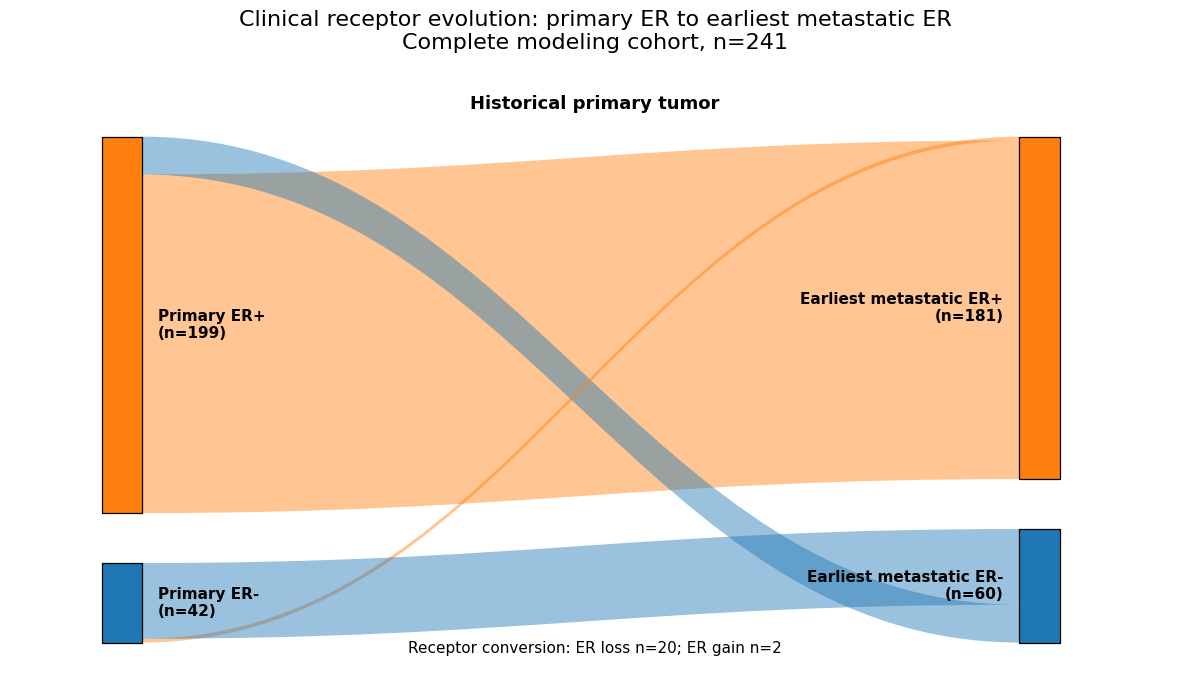

Saved: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Griffin/Downstream/AURORA_Griffin_Heldout_Test_ER/Ridge_M2_Sankey_outputs/Sankey2_heldout_ridge_M2_evaluation.png
Saved: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Griffin/Downstream/AURORA_Griffin_Heldout_Test_ER/Ridge_M2_Sankey_outputs/Sankey2_heldout_ridge_M2_evaluation.pdf


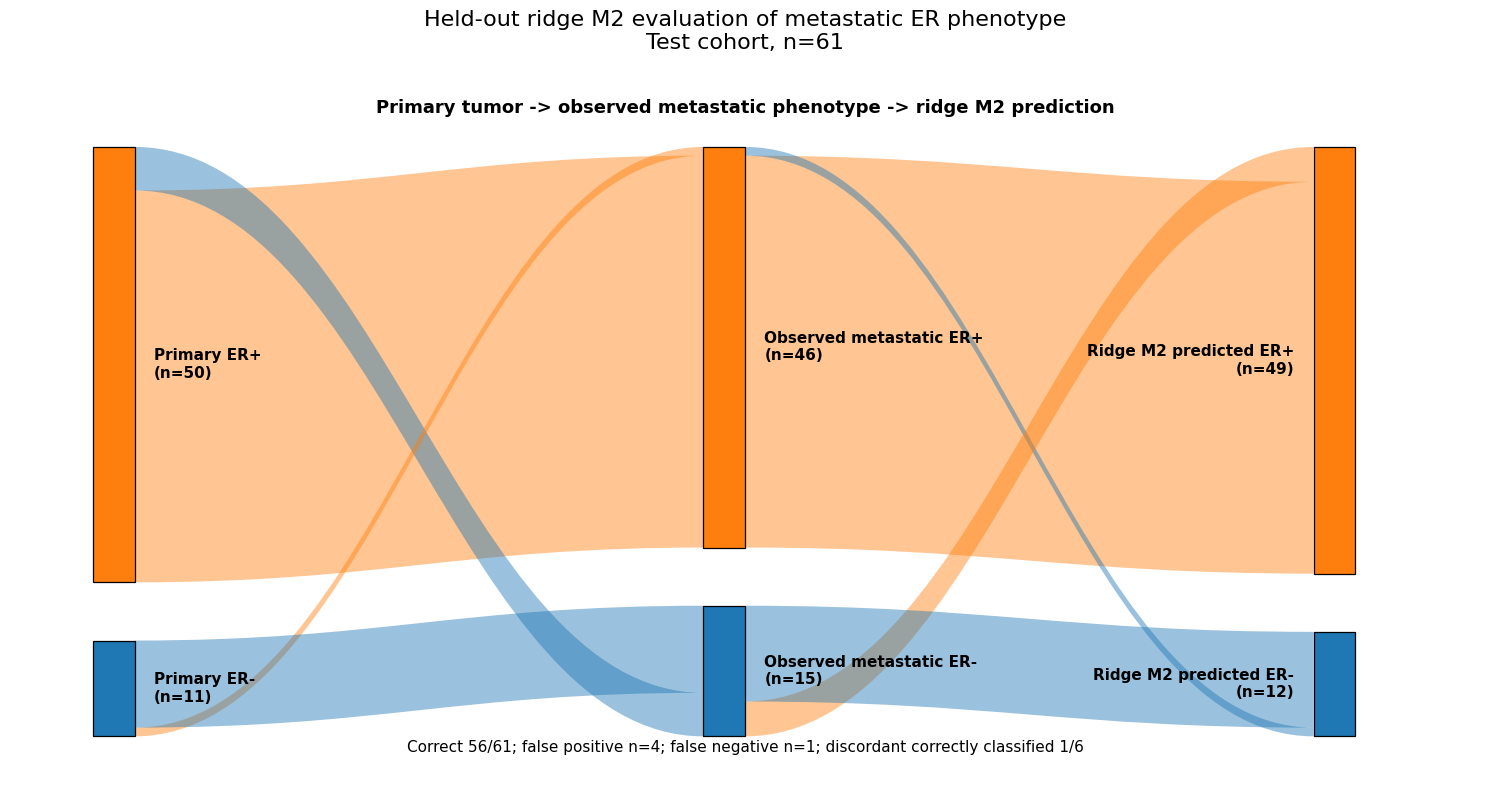


Completed both Sankey plots.


In [6]:
"""
AURORA metastatic ER Sankey plots
=================================

Creates two reproducible Sankey-style flow diagrams:

1. Clinical receptor evolution
   Historical primary-tumor ER -> earliest known metastatic ER
   Uses the complete modeling cohort from the fixed split manifest.

2. Held-out ridge M2 evaluation
   Primary-tumor ER -> observed metastatic ER -> ridge M2 prediction
   Uses only patients in the held-out prediction table.
"""

from __future__ import annotations

import argparse
from collections import defaultdict
from pathlib import Path
from typing import Dict, Iterable, List, Sequence, Tuple

import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.path import Path as MplPath
from matplotlib.patches import PathPatch, Rectangle


ER_ORDER = ["Positive", "Negative"]


def parse_args() -> argparse.Namespace:
    parser = argparse.ArgumentParser(
        description="Generate clinical-evolution and held-out ridge-M2 Sankey plots."
    )
    parser.add_argument(
        "--split-file",
        default="/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Griffin/Downstream/AURORA_Griffin_Heldout_Test_ER/Cohort_split.tsv",
        help="Fixed cohort split TSV containing primary and metastatic ER.",
    )
    parser.add_argument(
        "--prediction-file",
        default=(
            "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Griffin/Downstream/AURORA_Griffin_Heldout_Test_ER/"
            "Heldout_test_patient_predictions.tsv"
        ),
        help="Held-out patient prediction TSV.",
    )
    parser.add_argument(
        "--outdir",
        default="/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Griffin/Downstream/AURORA_Griffin_Heldout_Test_ER/Ridge_M2_Sankey_outputs",
        help="Output directory.",
    )
    parser.add_argument(
        "--dpi",
        type=int,
        default=300,
        help="PNG resolution.",
    )
    args, _unknown = parser.parse_known_args()
    return args


def normalize_er(value: object) -> str:
    """Normalize common ER encodings to Positive or Negative."""
    if pd.isna(value):
        raise ValueError("Missing ER value encountered.")

    text = str(value).strip().lower()
    positive = {
        "positive", "pos", "er+", "er positive", "1", "true",
    }
    negative = {
        "negative", "neg", "er-", "er−", "er negative", "0", "false",
    }

    if text in positive:
        return "Positive"
    if text in negative:
        return "Negative"

    raise ValueError(f"Unrecognized ER value: {value!r}")


def require_columns(df: pd.DataFrame, columns: Sequence[str], file_label: str) -> None:
    missing = [column for column in columns if column not in df.columns]
    if missing:
        raise KeyError(
            f"{file_label} is missing required columns: {missing}\n"
            f"Available columns: {list(df.columns)}"
        )


def make_node_layout(
    stages: Sequence[Sequence[str]],
    counts: Dict[str, int],
    total: int,
    bottom: float = 0.09,
    top: float = 0.90,
    gap: float = 0.08,
) -> Dict[str, Tuple[float, float]]:
    """
    Return {node: (y_bottom, height)}.

    Within each stage, Positive is placed above Negative.
    Node height is proportional to patient count.
    """
    usable = top - bottom
    scale = (usable - gap) / total
    layout: Dict[str, Tuple[float, float]] = {}

    for stage in stages:
        positive_node, negative_node = stage
        negative_height = counts[negative_node] * scale
        positive_height = counts[positive_node] * scale

        layout[negative_node] = (bottom, negative_height)
        layout[positive_node] = (
            bottom + negative_height + gap,
            positive_height,
        )

    return layout


def add_ribbon(
    ax,
    source_node: str,
    target_node: str,
    value: int,
    x_source: float,
    x_target: float,
    node_width: float,
    node_layout: Dict[str, Tuple[float, float]],
    outgoing_offsets: Dict[str, float],
    incoming_offsets: Dict[str, float],
    scale: float,
    facecolor: str,
    alpha: float = 0.45,
) -> None:
    """Draw one smooth Sankey ribbon."""
    height = value * scale
    source_y = node_layout[source_node][0] + outgoing_offsets[source_node]
    target_y = node_layout[target_node][0] + incoming_offsets[target_node]

    outgoing_offsets[source_node] += height
    incoming_offsets[target_node] += height

    x0 = x_source + node_width
    x1 = x_target
    bend = (x1 - x0) * 0.43

    vertices = [
        (x0, source_y),
        (x0 + bend, source_y),
        (x1 - bend, target_y),
        (x1, target_y),
        (x1, target_y + height),
        (x1 - bend, target_y + height),
        (x0 + bend, source_y + height),
        (x0, source_y + height),
        (x0, source_y),
    ]
    codes = [
        MplPath.MOVETO,
        MplPath.CURVE4,
        MplPath.CURVE4,
        MplPath.CURVE4,
        MplPath.LINETO,
        MplPath.CURVE4,
        MplPath.CURVE4,
        MplPath.CURVE4,
        MplPath.CLOSEPOLY,
    ]

    ax.add_patch(
        PathPatch(
            MplPath(vertices, codes),
            facecolor=facecolor,
            edgecolor="none",
            alpha=alpha,
            zorder=1,
        )
    )


def draw_nodes(
    ax,
    stages: Sequence[Sequence[str]],
    x_positions: Sequence[float],
    node_layout: Dict[str, Tuple[float, float]],
    counts: Dict[str, int],
    display_labels: Dict[str, str],
    node_width: float,
    positive_color: str,
    negative_color: str,
) -> None:
    """Draw nodes and labels above the ribbons."""
    for x, stage in zip(x_positions, stages):
        for node in stage:
            y, height = node_layout[node]
            color = positive_color if node.endswith("Positive") else negative_color
            ax.add_patch(
                Rectangle(
                    (x, y),
                    node_width,
                    height,
                    facecolor=color,
                    edgecolor="black",
                    linewidth=0.9,
                    zorder=4,
                )
            )

            place_left = x > 0.75
            text_x = x - 0.014 if place_left else x + node_width + 0.014
            horizontal = "right" if place_left else "left"

            ax.text(
                text_x,
                y + height / 2,
                f"{display_labels[node]}\n(n={counts[node]})",
                ha=horizontal,
                va="center",
                fontsize=11,
                fontweight="bold",
                zorder=5,
            )


def save_figure(fig, outbase: Path, dpi: int) -> None:
    png = outbase.with_suffix(".png")
    pdf = outbase.with_suffix(".pdf")
    fig.savefig(png, dpi=dpi, bbox_inches="tight")
    fig.savefig(pdf, bbox_inches="tight")
    print(f"Saved: {png}")
    print(f"Saved: {pdf}")


def clinical_receptor_evolution(
    split_file: Path,
    outdir: Path,
    dpi: int,
) -> None:
    """Plot Primary ER -> earliest metastatic ER for all modeled patients."""
    df = pd.read_csv(split_file, sep="\t")
    require_columns(
        df,
        ["patient_id", "Primary_tumor_ER", "Earliest_metastatic_ER"],
        "Split manifest",
    )

    df = df.copy()
    df["Primary_tumor_ER"] = df["Primary_tumor_ER"].map(normalize_er)
    df["Metastatic_ER"] = df["Earliest_metastatic_ER"].map(normalize_er)

    duplicate_patients = df["patient_id"].duplicated(keep=False)
    if duplicate_patients.any():
        duplicates = sorted(df.loc[duplicate_patients, "patient_id"].astype(str).unique())
        raise ValueError(
            "The clinical Sankey requires one row per patient. "
            f"Duplicated patient IDs: {duplicates[:10]}"
        )

    flow_table = (
        df.groupby(["Primary_tumor_ER", "Metastatic_ER"], observed=True)
        .size()
        .reindex(
            pd.MultiIndex.from_product(
                [ER_ORDER, ER_ORDER],
                names=["Primary_tumor_ER", "Metastatic_ER"],
            ),
            fill_value=0,
        )
        .rename("n")
        .reset_index()
    )
    flow_table["Discordance_type"] = flow_table.apply(
        lambda row: (
            "Concordant ER+"
            if row["Primary_tumor_ER"] == "Positive"
            and row["Metastatic_ER"] == "Positive"
            else "ER loss"
            if row["Primary_tumor_ER"] == "Positive"
            and row["Metastatic_ER"] == "Negative"
            else "ER gain"
            if row["Primary_tumor_ER"] == "Negative"
            and row["Metastatic_ER"] == "Positive"
            else "Concordant ER-"
        ),
        axis=1,
    )
    flow_table.to_csv(
        outdir / "Sankey1_clinical_receptor_evolution_counts.tsv",
        sep="\t",
        index=False,
    )

    stages = [
        ["Primary Positive", "Primary Negative"],
        ["Metastatic Positive", "Metastatic Negative"],
    ]
    counts = {
        "Primary Positive": int((df["Primary_tumor_ER"] == "Positive").sum()),
        "Primary Negative": int((df["Primary_tumor_ER"] == "Negative").sum()),
        "Metastatic Positive": int((df["Metastatic_ER"] == "Positive").sum()),
        "Metastatic Negative": int((df["Metastatic_ER"] == "Negative").sum()),
    }
    total = len(df)
    node_layout = make_node_layout(stages, counts, total)
    scale = (0.90 - 0.09 - 0.08) / total

    colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
    positive_color = colors[1 % len(colors)]
    negative_color = colors[0]
    x_positions = [0.08, 0.88]
    node_width = 0.035

    flows = [
        ("Primary Positive", "Metastatic Positive",
         int(((df["Primary_tumor_ER"] == "Positive") &
              (df["Metastatic_ER"] == "Positive")).sum()),
         positive_color),
        ("Primary Positive", "Metastatic Negative",
         int(((df["Primary_tumor_ER"] == "Positive") &
              (df["Metastatic_ER"] == "Negative")).sum()),
         negative_color),
        ("Primary Negative", "Metastatic Positive",
         int(((df["Primary_tumor_ER"] == "Negative") &
              (df["Metastatic_ER"] == "Positive")).sum()),
         positive_color),
        ("Primary Negative", "Metastatic Negative",
         int(((df["Primary_tumor_ER"] == "Negative") &
              (df["Metastatic_ER"] == "Negative")).sum()),
         negative_color),
    ]

    outgoing_offsets = defaultdict(float)
    incoming_offsets = defaultdict(float)

    fig, ax = plt.subplots(figsize=(12, 7))
    for source, target, value, color in flows:
        if value > 0:
            add_ribbon(
                ax=ax,
                source_node=source,
                target_node=target,
                value=value,
                x_source=x_positions[0],
                x_target=x_positions[1],
                node_width=node_width,
                node_layout=node_layout,
                outgoing_offsets=outgoing_offsets,
                incoming_offsets=incoming_offsets,
                scale=scale,
                facecolor=color,
            )

    draw_nodes(
        ax,
        stages,
        x_positions,
        node_layout,
        counts,
        {
            "Primary Positive": "Primary ER+",
            "Primary Negative": "Primary ER-",
            "Metastatic Positive": "Earliest metastatic ER+",
            "Metastatic Negative": "Earliest metastatic ER-",
        },
        node_width,
        positive_color,
        negative_color,
    )

    er_loss = int(
        ((df["Primary_tumor_ER"] == "Positive") &
         (df["Metastatic_ER"] == "Negative")).sum()
    )
    er_gain = int(
        ((df["Primary_tumor_ER"] == "Negative") &
         (df["Metastatic_ER"] == "Positive")).sum()
    )

    ax.text(
        0.50,
        0.965,
        "Historical primary tumor",
        transform=ax.transAxes,
        ha="center",
        va="top",
        fontsize=13,
        fontweight="bold",
    )
    ax.text(
        0.50,
        0.04,
        f"Receptor conversion: ER loss n={er_loss}; ER gain n={er_gain}",
        transform=ax.transAxes,
        ha="center",
        va="bottom",
        fontsize=11,
    )
    ax.set_title(
        "Clinical receptor evolution: primary ER to earliest metastatic ER\n"
        f"Complete modeling cohort, n={total}",
        fontsize=16,
        pad=18,
    )
    ax.set_xlim(0, 1.02)
    ax.set_ylim(0.03, 1.0)
    ax.axis("off")
    fig.tight_layout()
    save_figure(fig, outdir / "Sankey1_clinical_receptor_evolution", dpi)
    plt.show()
    plt.close(fig)


def heldout_model_evaluation(
    prediction_file: Path,
    outdir: Path,
    dpi: int,
) -> None:
    """Plot Primary ER -> observed metastatic ER -> ridge M2 prediction."""
    df = pd.read_csv(prediction_file, sep="\t")

    m2_prediction_column = "M2_predicted_ER"
    required = [
        "patient_id",
        "Primary_tumor_ER",
        "Observed_metastatic_ER",
        m2_prediction_column,
    ]
    require_columns(df, required, "Held-out prediction file")

    df = df.copy()
    for column in [
        "Primary_tumor_ER",
        "Observed_metastatic_ER",
        m2_prediction_column,
    ]:
        df[column] = df[column].map(normalize_er)

    duplicate_patients = df["patient_id"].duplicated(keep=False)
    if duplicate_patients.any():
        duplicates = sorted(df.loc[duplicate_patients, "patient_id"].astype(str).unique())
        raise ValueError(
            "The held-out Sankey requires one row per patient. "
            f"Duplicated patient IDs: {duplicates[:10]}"
        )

    flow_table = (
        df.groupby(
            [
                "Primary_tumor_ER",
                "Observed_metastatic_ER",
                m2_prediction_column,
            ],
            observed=True,
        )
        .size()
        .reindex(
            pd.MultiIndex.from_product(
                [ER_ORDER, ER_ORDER, ER_ORDER],
                names=[
                    "Primary_tumor_ER",
                    "Observed_metastatic_ER",
                    "M2_predicted_ER",
                ],
            ),
            fill_value=0,
        )
        .rename("n")
        .reset_index()
    )
    flow_table["Correct"] = (
        flow_table["Observed_metastatic_ER"] == flow_table["M2_predicted_ER"]
    )
    flow_table.to_csv(
        outdir / "Sankey2_heldout_ridge_M2_flow_counts.tsv",
        sep="\t",
        index=False,
    )

    stages = [
        ["Primary Positive", "Primary Negative"],
        ["Observed Positive", "Observed Negative"],
        ["Predicted Positive", "Predicted Negative"],
    ]
    counts = {
        "Primary Positive": int((df["Primary_tumor_ER"] == "Positive").sum()),
        "Primary Negative": int((df["Primary_tumor_ER"] == "Negative").sum()),
        "Observed Positive": int((df["Observed_metastatic_ER"] == "Positive").sum()),
        "Observed Negative": int((df["Observed_metastatic_ER"] == "Negative").sum()),
        "Predicted Positive": int((df[m2_prediction_column] == "Positive").sum()),
        "Predicted Negative": int((df[m2_prediction_column] == "Negative").sum()),
    }
    total = len(df)
    node_layout = make_node_layout(stages, counts, total)
    scale = (0.90 - 0.09 - 0.08) / total

    colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
    positive_color = colors[1 % len(colors)]
    negative_color = colors[0]
    x_positions = [0.06, 0.50, 0.94]
    node_width = 0.030

    # Stage 1: primary -> observed metastatic
    stage1 = [
        ("Primary Positive", "Observed Positive",
         int(((df["Primary_tumor_ER"] == "Positive") &
              (df["Observed_metastatic_ER"] == "Positive")).sum()),
         positive_color),
        ("Primary Positive", "Observed Negative",
         int(((df["Primary_tumor_ER"] == "Positive") &
              (df["Observed_metastatic_ER"] == "Negative")).sum()),
         negative_color),
        ("Primary Negative", "Observed Positive",
         int(((df["Primary_tumor_ER"] == "Negative") &
              (df["Observed_metastatic_ER"] == "Positive")).sum()),
         positive_color),
        ("Primary Negative", "Observed Negative",
         int(((df["Primary_tumor_ER"] == "Negative") &
              (df["Observed_metastatic_ER"] == "Negative")).sum()),
         negative_color),
    ]

    # Stage 2: observed metastatic -> ridge M2 prediction
    stage2 = [
        ("Observed Positive", "Predicted Positive",
         int(((df["Observed_metastatic_ER"] == "Positive") &
              (df[m2_prediction_column] == "Positive")).sum()),
         positive_color),
        ("Observed Positive", "Predicted Negative",
         int(((df["Observed_metastatic_ER"] == "Positive") &
              (df[m2_prediction_column] == "Negative")).sum()),
         negative_color),
        ("Observed Negative", "Predicted Positive",
         int(((df["Observed_metastatic_ER"] == "Negative") &
              (df[m2_prediction_column] == "Positive")).sum()),
         positive_color),
        ("Observed Negative", "Predicted Negative",
         int(((df["Observed_metastatic_ER"] == "Negative") &
              (df[m2_prediction_column] == "Negative")).sum()),
         negative_color),
    ]

    fig, ax = plt.subplots(figsize=(15, 8))

    outgoing_offsets = defaultdict(float)
    incoming_offsets = defaultdict(float)
    for source, target, value, color in stage1:
        if value > 0:
            add_ribbon(
                ax=ax,
                source_node=source,
                target_node=target,
                value=value,
                x_source=x_positions[0],
                x_target=x_positions[1],
                node_width=node_width,
                node_layout=node_layout,
                outgoing_offsets=outgoing_offsets,
                incoming_offsets=incoming_offsets,
                scale=scale,
                facecolor=color,
            )

    # New stacking offsets for the second transition.
    outgoing_offsets = defaultdict(float)
    incoming_offsets = defaultdict(float)
    for source, target, value, color in stage2:
        if value > 0:
            add_ribbon(
                ax=ax,
                source_node=source,
                target_node=target,
                value=value,
                x_source=x_positions[1],
                x_target=x_positions[2],
                node_width=node_width,
                node_layout=node_layout,
                outgoing_offsets=outgoing_offsets,
                incoming_offsets=incoming_offsets,
                scale=scale,
                facecolor=color,
            )

    draw_nodes(
        ax,
        stages,
        x_positions,
        node_layout,
        counts,
        {
            "Primary Positive": "Primary ER+",
            "Primary Negative": "Primary ER-",
            "Observed Positive": "Observed metastatic ER+",
            "Observed Negative": "Observed metastatic ER-",
            "Predicted Positive": "Ridge M2 predicted ER+",
            "Predicted Negative": "Ridge M2 predicted ER-",
        },
        node_width,
        positive_color,
        negative_color,
    )

    observed = df["Observed_metastatic_ER"]
    predicted = df[m2_prediction_column]
    primary = df["Primary_tumor_ER"]

    correct = int((observed == predicted).sum())
    discordant = primary != observed
    discordant_total = int(discordant.sum())
    discordant_correct = int(((observed == predicted) & discordant).sum())
    false_positive = int(((observed == "Negative") & (predicted == "Positive")).sum())
    false_negative = int(((observed == "Positive") & (predicted == "Negative")).sum())

    ax.text(
        0.50,
        0.965,
        "Primary tumor -> observed metastatic phenotype -> ridge M2 prediction",
        transform=ax.transAxes,
        ha="center",
        va="top",
        fontsize=13,
        fontweight="bold",
    )
    ax.text(
        0.50,
        0.035,
        (
            f"Correct {correct}/{total}; false positive n={false_positive}; "
            f"false negative n={false_negative}; "
            f"discordant correctly classified {discordant_correct}/{discordant_total}"
        ),
        transform=ax.transAxes,
        ha="center",
        va="bottom",
        fontsize=11,
    )
    ax.set_title(
        "Held-out ridge M2 evaluation of metastatic ER phenotype\n"
        f"Test cohort, n={total}",
        fontsize=16,
        pad=18,
    )
    ax.set_xlim(0, 1.06)
    ax.set_ylim(0.03, 1.0)
    ax.axis("off")
    fig.tight_layout()
    save_figure(fig, outdir / "Sankey2_heldout_ridge_M2_evaluation", dpi)
    plt.show()
    plt.close(fig)


def write_run_summary(
    split_file: Path,
    prediction_file: Path,
    outdir: Path,
) -> None:
    split_df = pd.read_csv(split_file, sep="\t")
    pred_df = pd.read_csv(prediction_file, sep="\t")

    require_columns(
        split_df,
        ["set", "Primary_tumor_ER", "Earliest_metastatic_ER"],
        "Split manifest",
    )

    split_counts = split_df["set"].value_counts(dropna=False).to_dict()
    discordance = (
        split_df.assign(
            Discordant_normalized=(
                split_df["Primary_tumor_ER"].map(normalize_er)
                != split_df["Earliest_metastatic_ER"].map(normalize_er)
            )
        )
        .groupby("set")["Discordant_normalized"]
        .agg(["count", "sum"])
    )

    summary_lines = [
        "AURORA Sankey plot run summary",
        "================================",
        f"Split file: {split_file}",
        f"Prediction file: {prediction_file}",
        "",
        f"Complete modeling cohort: n={len(split_df)}",
        f"Development cohort: n={split_counts.get('Development', 0)}",
        f"Held-out test cohort: n={split_counts.get('Held-out test', 0)}",
        "",
        "Discordant cases by set:",
        discordance.to_string(),
        "",
        f"Held-out prediction rows: n={len(pred_df)}",
    ]
    (outdir / "Sankey_run_summary.txt").write_text(
        "\n".join(summary_lines),
        encoding="utf-8",
    )


def main() -> None:
    args = parse_args()
    split_file = Path(args.split_file)
    prediction_file = Path(args.prediction_file)
    outdir = Path(args.outdir)
    outdir.mkdir(parents=True, exist_ok=True)

    if not split_file.exists():
        raise FileNotFoundError(f"Split file not found: {split_file}")
    if not prediction_file.exists():
        raise FileNotFoundError(f"Prediction file not found: {prediction_file}")

    clinical_receptor_evolution(split_file, outdir, args.dpi)
    heldout_model_evaluation(prediction_file, outdir, args.dpi)
    write_run_summary(split_file, prediction_file, outdir)

    print("\nCompleted both Sankey plots.")


if __name__ == "__main__":
    main()